<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-13/lab-076-nn-tomography.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 076. A neural network that denoises quantum state tomography

Quantum state tomography reconstructs the density matrix of a device from the frequencies of measured bit strings. With many shots per measurement setting the frequencies approach the Born probabilities and linear inversion returns the state. A real experiment has a limited budget of shots, and with a few shots per setting the linear-inversion estimate fluctuates strongly and has negative eigenvalues. Projecting it onto the physical states, or maximising the likelihood among them, gives a valid density matrix, but its average over many repetitions of the experiment no longer coincides with the true state. A pure state is an extreme point of the set of density matrices, so a mean of physical estimates equals it only if every estimate does. Any spread of the estimates moves their mean towards mixed states. A neural network trained on many pairs of a noisy estimate and the true state can learn to move the estimate back towards the state from which the data came. The network then acts as a learned correction, conditioned on the estimate, of the bias of the physical estimators.

We reimplement the attention-based tomography of Ref. [1] in a reduced form. We are given simulated measurement records of two qubits in the $3^N$ Pauli settings with $M$ shots per setting. For the training states we also know the true states, which a simulation knows and an experiment does not. We compute the linear-inversion estimate and its projection onto physical states and represent states by their Cholesky factors. We then train two networks with the same number of parameters, a multilayer perceptron (MLP) and a network with one self-attention block. We compare their fidelities with those of linear inversion and maximum likelihood for $M=10$, $100$ and $1000$, and test them on depolarised states that differ from the training set. We then scale the same code to four qubits and test the network on one-axis-twisted states, prepared by an interaction that couples all spins pairwise. Their entanglement is assessed through the quantum Fisher information, which for a pure state is four times the largest variance of a collective spin component.

Section 1 loads the libraries. Sections 2 and 3 build the measurement, linear inversion, the projection and maximum likelihood, and Section 4 samples random training states. Section 5 shows the bias of the physical estimates, and Section 6 introduces the Cholesky representation and the loss with its bound on the Bures distance. Sections 7 to 9 prepare the data, define the two networks and train them at $M=100$, Section 10 compares the fidelities and Section 11 tests depolarised states. Sections 1 to 11 form the core route. For work at home, Section 12 repeats the training for $M=10$ and $M=1000$ in about one minute, Section 13 treats four qubits and one-axis twisting in two to three minutes, and Section 14 shows published results of Ref. [1] and relates them to other neural-network approaches.

Ref. [1] uses convolutional layers before and after a transformer block and trains on a GPU. It tests square-root measurements of a qutrit pair and Pauli data of four qubits, where the test data also contain depolarisation and calibration errors. Our networks embed the rows of the Cholesky factor directly into one attention block. They see only multinomial shot noise and train on 5000 states with 800 Adam steps for two qubits and 1500 for four qubits on a laptop CPU. Our numbers are therefore classroom results and are reported separately from the published ones of Section 14. All quantities come from simulated measurement records with fixed random seeds, and the fidelities are evaluated against the true states, which only a simulation can do.

## 1. Libraries and arithmetic precision

NumPy prepares the states, simulates the measurements and evaluates fidelities in double precision. JAX runs the networks, their gradients and the maximum-likelihood iteration on the CPU in its default single precision, `float32` and `complex64`. Single precision is sufficient for the networks, because their errors are many orders of magnitude larger than the rounding errors. For the maximum-likelihood iteration Section 10 compares single precision with a double-precision reference. Matplotlib draws the figures, and the cells run in order.

The code uses three JAX constructs beyond `jax.grad`, `jax.jit` and `jax.vmap`. A Python `for` loop inside a compiled function is unrolled into one long program that takes long to compile, so JAX provides loops that are compiled once. The call `jax.lax.fori_loop(0, n, body, x)` applies `x = body(i, x)` for `i` from `0` to `n - 1` and returns the last `x`, and we use it for the maximum-likelihood iteration. The call `jax.lax.scan(step, carry, inputs)` works in the same way with a function of the form `carry, output = step(carry, input)`. Every call receives the carry of the previous call and the next slice of `inputs` along their first axis, and `scan` returns the last carry together with all outputs stacked in one array. In the training loop of Section 9 the carry holds the network parameters and the two running averages of Adam, the inputs are the step number and the indices of a mini-batch, and the outputs are the loss values. The network parameters are stored in nested dictionaries and lists of arrays, a structure that JAX calls a pytree. The call `jax.tree_util.tree_map(f, a, b)` applies `f` to every array of `a` together with the array of `b` at the same place and returns the results in the same nested structure, so a single line updates all parameters.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"   # small networks; the CPU avoids GPU memory allocation
import json, time
from functools import partial
from pathlib import Path
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

# JAX stays in single precision (float32, complex64) for the networks and the MLE iteration;
# states, Born probabilities and fidelities are computed with NumPy in double precision
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("classroom_results"); RES.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.labelsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11,
                     "legend.fontsize": 11, "figure.figsize": (4.6, 3.1), "savefig.bbox": "tight",
                     "pdf.fonttype": 42, "ps.fonttype": 42})
# estimator colours: true state black, LI raw grey, LI + projection green, MLE orange, MLP sky, attention network blue
# other series (shot numbers, thresholds) use navy, purple and teal
COL = dict(truth="black", li="#9AA0A6", proj="#1B7F36", mle="#D35A05", mlp="#3E8FD0", attn="#005CA7",
           navy="#002B5C", purple="#6A3D9A", teal="#1B9E77")
SLIDE_RC = {"font.size": 12.5, "axes.labelsize": 12.5, "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12}
def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=150)
def panels(name, draws):
    # notes: panels side by side at 7.0 x 2.9 in, 11 pt; slides: every panel also as its own file at 4.6 x 3.1 in, 12-13 pt
    fig, axes = plt.subplots(1, len(draws), figsize=(7.0, 2.9))
    for ax, draw, lab in zip(axes, draws, "abcdef"):
        draw(ax, f"({lab})")
    fig.tight_layout(); save(fig, name); plt.show()
    for draw, lab in zip(draws, "abcdef"):
        with plt.rc_context(SLIDE_RC):
            single, ax = plt.subplots(figsize=(4.6, 3.1))
            draw(ax, None)
            single.tight_layout(); save(single, f"{name}_{lab}"); plt.close(single)
started = time.perf_counter()
NUMBERS = {}
rng = np.random.default_rng(76)       # random states and shot noise
key = jax.random.PRNGKey(76)          # network initialisation
print("JAX", jax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | devices: [CpuDevice(id=0)]


## 2. Pauli measurements and linear inversion

A device prepares an unknown state $\hat\rho$ of $N$ qubits. In a measurement setting $s=(s_0,\dots,s_{N-1})$ every qubit $q$ is measured along one of the axes $s_q\in\{X,Y,Z\}$, by a rotation followed by a measurement in the computational basis. For $X$ the rotation is the Hadamard gate $\hat H$ and for $Y$ it is $\hat S^\dagger$ followed by $\hat H$. Each of the $3^N$ settings returns a bit string $\mathbf b=b_0b_1\dots b_{N-1}$, one of $2^N$ values, with the Born probability
$$p_s(\mathbf b)=\mathrm{Tr}\big[\hat\rho\,\hat\pi_{s,\mathbf b}\big] , \tag{1}$$
where the projector of outcome $\mathbf b$ in setting $s$ is the product of single-qubit projectors,
$$\hat\pi_{s,\mathbf b}=\bigotimes_{q=0}^{N-1}\frac{\hat I+(-1)^{b_q}\hat\sigma_{s_q}}{2} . \tag{2}$$
Bit $0$ corresponds to the eigenvalue $+1$ of the Pauli matrix $\hat\sigma_{s_q}$, and qubit 0 is the leftmost factor. With $M$ shots per setting the device returns counts $n_s(\mathbf b)$, and the frequencies $f_s(\mathbf b)=n_s(\mathbf b)/M$ estimate the probabilities. The counts of one setting follow a multinomial distribution with $M$ trials and probabilities $p_s(\mathbf b)$.

For one qubit the state is fixed by its Bloch vector, $\hat\rho=\tfrac12\big(\hat I+\sum_ar_a\hat\sigma_a\big)$ with $r_a=p_a(0)-p_a(1)$, the mean of the measured eigenvalue along axis $a$. Inserting $\hat\pi_{a,0}+\hat\pi_{a,1}=\hat I$ and $\hat\pi_{a,0}-\hat\pi_{a,1}=\hat\sigma_a$ rewrites this relation as a linear combination of the probabilities,
$$\hat\rho=\frac13\sum_{a\in\{X,Y,Z\}}\sum_{b\in\{0,1\}}p_a(b)\,\big(3\hat\pi_{a,b}-\hat I\big) , \tag{3}$$
which can be checked by summing over $b$, since $\sum_bp_a(b)=1$. For $N$ qubits the projectors (2) are products of single-qubit projectors and equation (3) is linear in the probabilities, so the same inversion applies to every qubit separately and the operator that multiplies $p_s(\mathbf b)$ becomes a product of the single-qubit operators $(3\hat\pi_{a,b}-\hat I)/3$. Replacing the probabilities by the measured frequencies gives the linear-inversion estimate
$$\tilde\rho_{\mathrm{LI}}=\sum_s\sum_{\mathbf b}f_s(\mathbf b)\,\hat D_{s,\mathbf b},\qquad \hat D_{s,\mathbf b}=\frac1{3^N}\bigotimes_{q=0}^{N-1}\big(3\hat\pi_{s_q,b_q}-\hat I\big) . \tag{4}$$
It is equivalent to estimating every Pauli expectation value from all settings that measure it and summing the Pauli strings with these coefficients. The estimate is linear in the data, its mean over repeated experiments is the true state, and its fluctuations decrease as $M^{-1/2}$. A state of two qubits has $d^2-1=15$ real parameters, with $d=2^N$, and the nine settings provide 36 frequencies.

The code builds all projectors (2) and operators $\hat D_{s,\mathbf b}$ once, checks that exact probabilities invert to the state, and applies equation (4) to 100 shots per setting of the maximally entangled state $|\Phi_i\rangle=(|00\rangle+i|11\rangle)/\sqrt2$.

In [2]:
I2 = np.eye(2, dtype=complex)
PAULI = {"X": np.array([[0, 1], [1, 0]], complex), "Y": np.array([[0, -1j], [1j, 0]]), "Z": np.diag([1.0, -1.0]).astype(complex)}

def kron_all(mats):
    out = np.ones((1, 1), complex)
    for m in mats:
        out = np.kron(out, m)          # qubit 0 is the leftmost factor
    return out

def setting_axes(s, N):
    # setting index s = sum_q a_q 3^(N-1-q) -> measured axis of every qubit
    return [("X", "Y", "Z")[(s // 3 ** (N - 1 - q)) % 3] for q in range(N)]

def pauli_measurement(N):
    # PI[k]: projector (2) of outcome b in setting s; DUAL[k]: operator D_{s,b} of equation (4); k = s 2^N + b
    PI, DUAL = [], []
    for s in range(3 ** N):
        axes = setting_axes(s, N)
        for b in range(2 ** N):
            bits = [(b >> (N - 1 - q)) & 1 for q in range(N)]
            proj = [(I2 + (-1) ** bq * PAULI[a]) / 2 for a, bq in zip(axes, bits)]
            PI.append(kron_all(proj))
            DUAL.append(kron_all([3 * p - I2 for p in proj]) / 3 ** N)
    return np.array(PI), np.array(DUAL)

def born(rho, PI, N):
    # p_s(b) = Tr[rho pi_{s,b}], equation (1), for a batch of states; shape (batch, 3^N, 2^N)
    d = 2 ** N
    p = (rho.reshape(len(rho), -1) @ PI.transpose(0, 2, 1).reshape(len(PI), -1).T).real
    return p.reshape(len(rho), 3 ** N, d)

def measure(rho, PI, N, M):
    # M shots in every setting: multinomial counts -> frequencies f_s(b), flattened to (batch, 3^N 2^N)
    p = np.clip(born(rho, PI, N), 0, None)
    p /= p.sum(-1, keepdims=True)
    return (rng.multinomial(M, p) / M).reshape(len(rho), -1)

def linear_inversion(f, DUAL):
    d = DUAL.shape[-1]
    return (f @ DUAL.reshape(len(DUAL), -1)).reshape(len(f), d, d)      # equation (4)

N2 = 2; d2 = 2 ** N2
PI2, DUAL2 = pauli_measurement(N2)
print(f"N = {N2}: {3 ** N2} settings x {2 ** N2} outcomes = {len(PI2)} frequencies, {d2 ** 2 - 1} real parameters of the state")
# checks: the outcomes of each setting add up to the identity, and exact probabilities invert to the state
assert np.allclose(PI2.reshape(3 ** N2, d2, d2, d2).sum(1), np.eye(d2))
psi_phi = np.array([1, 0, 0, 1j]) / np.sqrt(2)
rho_phi = np.outer(psi_phi, psi_phi.conj())
assert np.allclose(linear_inversion(born(rho_phi[None], PI2, N2).reshape(1, -1), DUAL2)[0], rho_phi)
f_demo = measure(rho_phi[None], PI2, N2, 100)
rho_li_demo = linear_inversion(f_demo, DUAL2)[0]
eig_demo = np.linalg.eigvalsh(rho_li_demo)
print("|Phi_i> = (|00> + i|11>)/sqrt2, M = 100 shots per setting")
print("eigenvalues of the linear-inversion estimate:", np.round(eig_demo, 3))
NUMBERS.update(DemoMinEig=f"{eig_demo[0]:.3f}")

N = 2: 9 settings x 4 outcomes = 36 frequencies, 15 real parameters of the state
|Phi_i> = (|00> + i|11>)/sqrt2, M = 100 shots per setting
eigenvalues of the linear-inversion estimate: [-0.053 -0.003  0.045  1.011]


## 3. Projection, fidelity and maximum likelihood

The estimate of $|\Phi_i\rangle$ has unit trace, but two of its eigenvalues are negative, so it is no density matrix. The nearest density matrix in the Hilbert–Schmidt norm keeps the eigenvectors of $\tilde\rho_{\mathrm{LI}}$ and replaces its eigenvalues $\lambda_i$ by [2]
$$\lambda_i'=\max(\lambda_i-x,\,0),\qquad \text{with } x \text{ fixed by } \sum_i\lambda_i'=1 . \tag{5}$$
Negative and small eigenvalues are set to zero, and the removed weight is subtracted evenly from the remaining ones. We call the result $\tilde\rho_{\mathrm{proj}}$. It costs one diagonalisation of a $d\times d$ matrix.

We measure the quality of an estimate $\hat\sigma$ of the true state $\hat\rho$ by the fidelity [3,4]
$$F(\hat\rho,\hat\sigma)=\Big(\mathrm{Tr}\sqrt{\sqrt{\hat\rho}\,\hat\sigma\sqrt{\hat\rho}}\Big)^2 , \tag{6}$$
which equals one only for $\hat\sigma=\hat\rho$ and reduces to $\langle\psi|\hat\sigma|\psi\rangle$ for a pure state $\hat\rho=|\psi\rangle\langle\psi|$. It is defined only for physical $\hat\sigma$, which is one more reason to project.

Maximum-likelihood estimation (MLE) searches among the physical states for the one under which the observed counts are most probable. The log-likelihood is $\ell(\hat\sigma)=\sum_{s,\mathbf b}n_s(\mathbf b)\ln p_s(\mathbf b|\hat\sigma)$, in nats, and its maximum is found by the $R\rho R$ iteration [5,6]
$$\hat\sigma\;\leftarrow\;\frac{\hat R\hat\sigma\hat R}{\mathrm{Tr}\big(\hat R\hat\sigma\hat R\big)},\qquad \hat R=\frac1{3^N}\sum_{s,\mathbf b}\frac{f_s(\mathbf b)}{p_s(\mathbf b|\hat\sigma)}\,\hat\pi_{s,\mathbf b} , \tag{7}$$
started from the maximally mixed state $\hat I/d$. At the maximum the ratios $f/p$ make $\hat R$ act as the identity on the support of $\hat\sigma$, and the iteration stops changing the state. We run 1000 iterations in single precision, vectorised over many data sets with JAX, and Section 10 checks this choice against 4000 iterations and against double precision.

In [3]:
def project_physical(rho):
    # equation (5), Ref. [2]: keep the eigenvectors, project the eigenvalues onto {l_i >= 0, sum_i l_i = 1}
    w, v = np.linalg.eigh(rho)
    u = w[:, ::-1]                                           # descending
    css = np.cumsum(u, 1); j = np.arange(1, u.shape[1] + 1)
    ok = u - (css - 1) / j > 0
    k = ok.shape[1] - np.argmax(ok[:, ::-1], axis=1)         # number of eigenvalues that stay positive
    x = (css[np.arange(len(u)), k - 1] - 1) / k
    lam = np.clip(w - x[:, None], 0, None)
    return np.einsum("bik,bk,bjk->bij", v, lam, v.conj())

def fidelity(rho, sigma):
    # equation (6) for batches of states
    w, v = np.linalg.eigh(rho)
    s = np.einsum("bik,bk,bjk->bij", v, np.sqrt(np.clip(w, 0, None)), v.conj())
    lam = np.linalg.eigvalsh(s @ sigma @ s)
    return np.sum(np.sqrt(np.clip(lam, 0, None)), 1) ** 2

@partial(jax.jit, static_argnums=(2, 3))
def rhor_iteration(f, PI, N, iterations=1000):
    # equation (7), started from the maximally mixed state
    d = 2 ** N
    PI = jnp.asarray(PI, jnp.complex64); f = jnp.asarray(f, jnp.float32)
    def body(_, sigma):
        p = jnp.real(jnp.einsum("kij,bji->bk", PI, sigma))
        R = jnp.einsum("bk,kij->bij", f / jnp.maximum(p, 1e-12), PI) / 3 ** N
        sigma = R @ sigma @ R
        return sigma / jnp.real(jnp.trace(sigma, axis1=1, axis2=2))[:, None, None]
    sigma0 = jnp.broadcast_to(jnp.eye(d, dtype=jnp.complex64) / d, (f.shape[0], d, d))
    return jax.lax.fori_loop(0, iterations, body, sigma0)

def mle(f, PI, N, iterations=1000):
    return np.asarray(rhor_iteration(f, PI, N, iterations), np.complex128)

rho_proj_demo = project_physical(rho_li_demo[None])[0]
rho_mle_demo = mle(f_demo, PI2, N2)[0]
assert abs(np.trace(rho_proj_demo) - 1) < 1e-12 and np.linalg.eigvalsh(rho_proj_demo)[0] > -1e-12
for name, r in (("projection", rho_proj_demo), ("MLE", rho_mle_demo)):
    print(f"{name:10s}: eigenvalues {np.round(np.linalg.eigvalsh(r), 3)}, fidelity with |Phi_i> {fidelity(rho_phi[None], r[None])[0]:.4f}")

projection: eigenvalues [-0.     0.     0.017  0.983], fidelity with |Phi_i> 0.9723
MLE       : eigenvalues [-0. -0.  0.  1.], fidelity with |Phi_i> 0.9940


The projection sets the two negative eigenvalues to zero and lowers both positive ones by the same amount, from $0.045$ to $0.017$ and from $1.011$ to $0.983$, which keeps the trace equal to one. MLE returns a state close to pure. Both are physical, and both start from the same 36 frequencies.

## 4. Random states for training

A network that corrects estimates of arbitrary states has to see many different states during training. We use two families that cover the state space without preferring any direction. Haar-random pure states are pure states distributed uniformly over the unit sphere of $\mathbb C^d$, so their distribution is invariant under every unitary. We obtain them from the QR decomposition of a matrix $G$ with independent complex Gaussian entries [7]. Writing $G=QR$ and multiplying each column of $Q$ by the phase of the corresponding diagonal element of $R$ gives a Haar-random unitary $\hat U$, and its first column $\hat U|0\rangle$ is a Haar-random state. Mixed states are drawn from the Hilbert–Schmidt ensemble [8],
$$\hat\rho=\frac{GG^\dagger}{\mathrm{Tr}\,GG^\dagger} , \tag{8}$$
with the same kind of Gaussian matrix $G$. These states have full rank, and their mean purity $\mathrm{Tr}\,\hat\rho^2$ is $2d/(d^2+1)$, about $0.47$ for two qubits [8]. The training set of two qubits contains equal numbers of both kinds, so the network meets pure states on the boundary of the state space and typical mixed states inside it.

In [4]:
def haar_pure(B, d):
    # Ref. [7]: complex Gaussian G = QR, phases of diag(R) moved into Q -> Haar unitary U; state = first column U|0>
    G = (rng.normal(size=(B, d, d)) + 1j * rng.normal(size=(B, d, d))) / np.sqrt(2)
    Q, R = np.linalg.qr(G)
    ph = np.diagonal(R, axis1=1, axis2=2)
    psi = (Q * (ph / np.abs(ph))[:, None, :])[:, :, 0]
    return np.einsum("bi,bj->bij", psi, psi.conj())

def hs_mixed(B, d):
    # equation (8), Ref. [8]
    G = rng.normal(size=(B, d, d)) + 1j * rng.normal(size=(B, d, d))
    r = G @ G.conj().transpose(0, 2, 1)
    return r / np.trace(r, axis1=1, axis2=2).real[:, None, None]

def purity(rho):
    return np.einsum("bij,bji->b", rho, rho).real

pur_hs = purity(hs_mixed(4000, d2)).mean()
print(f"mean purity: Haar {purity(haar_pure(10, d2)).mean():.3f}, Hilbert-Schmidt {pur_hs:.3f}"
      f" (exact 2d/(d^2+1) = {2 * d2 / (d2 ** 2 + 1):.3f})")
NUMBERS.update(PurityHS=f"{pur_hs:.2f}")

mean purity: Haar 1.000, Hilbert-Schmidt 0.472 (exact 2d/(d^2+1) = 0.471)


## 5. The bias of physical estimates

Linear inversion is unbiased, since equation (4) is linear in the frequencies and the mean frequency is the probability. For a pure state its estimate has a negative eigenvalue in almost every run, because the true eigenvalues $0$ are surrounded by noise of both signs. The projection (5) sets the negative eigenvalues, and positive ones smaller than the shift $x$, to zero and lowers all remaining ones by $x$, and its result is a pure state only in a minority of runs. A pure state is an extreme point of the convex set of density matrices, which means that it cannot be written as a mixture of other states. A mean of physical estimates therefore equals a pure state only if every estimate equals it, and any spread of the estimates moves their mean towards mixed states. The errors of many repetitions do not average out, and the mean of the physical estimates lies away from the true state. This systematic error is a bias, and it is largest for states close to the boundary of the state space, such as pure states [1]. Every estimator that always returns a physical state has such a bias near the boundary, MLE included [1].

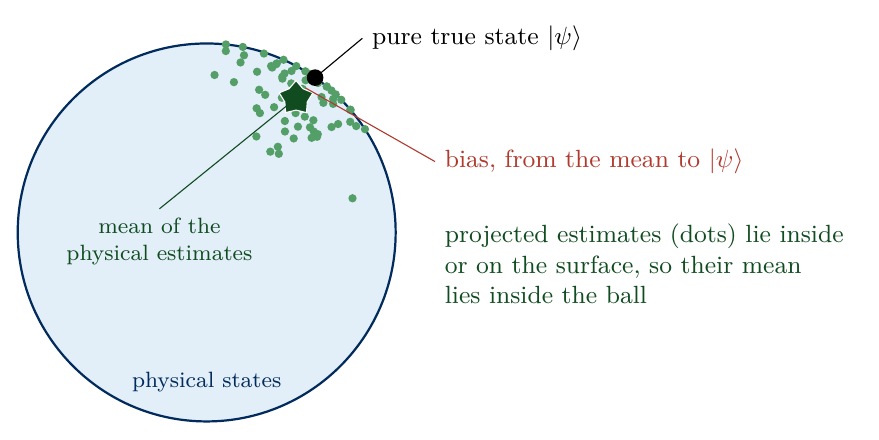

*Projected estimates of a pure state $|\psi\rangle$ lie inside the set of physical states or on its surface. Their mean (star) therefore lies inside, displaced from $|\psi\rangle$, and this displacement is the bias.*

The cell measures 1000 Haar-random pure states of two qubits for three shot numbers. It records the fraction of unphysical linear-inversion estimates, the purity before and after the projection and the fraction of projected estimates that are pure, with a single nonzero eigenvalue.

M =   10: unphysical LI 1.000, mean purity LI 1.217, after projection 0.881, pure after projection 0.21, fidelity after projection 0.882
M =  100: unphysical LI 1.000, mean purity LI 1.021, after projection 0.943, pure after projection 0.11, fidelity after projection 0.965
M = 1000: unphysical LI 1.000, mean purity LI 1.002, after projection 0.979, pure after projection 0.08, fidelity after projection 0.989


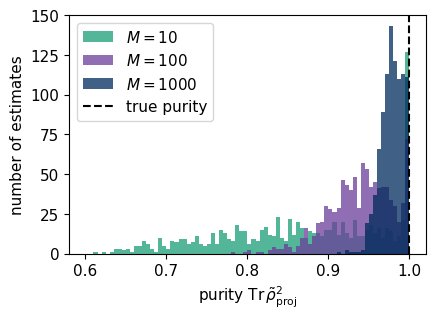

In [5]:
M_LIST = (10, 100, 1000)
bias = {}
rho_b = haar_pure(1000, d2)
for M in M_LIST:
    r_li = linear_inversion(measure(rho_b, PI2, N2, M), DUAL2)
    r_p = project_physical(r_li)
    rank_one = float(np.mean(np.sum(np.linalg.eigvalsh(r_p) > 1e-10, axis=1) == 1))
    bias[M] = dict(unphysical=float(np.mean(np.linalg.eigvalsh(r_li)[:, 0] < -1e-12)), purity_li=purity(r_li),
                   purity_proj=purity(r_p), fidelity_proj=fidelity(rho_b, r_p), pure_fraction=rank_one)
    print(f"M = {M:4d}: unphysical LI {bias[M]['unphysical']:.3f}, mean purity LI {bias[M]['purity_li'].mean():.3f},"
          f" after projection {bias[M]['purity_proj'].mean():.3f}, pure after projection {rank_one:.2f},"
          f" fidelity after projection {bias[M]['fidelity_proj'].mean():.3f}")
NUMBERS.update(PurityProjTen=f"{bias[10]['purity_proj'].mean():.2f}", PurityProjHundred=f"{bias[100]['purity_proj'].mean():.2f}",
               PurityProjThousand=f"{bias[1000]['purity_proj'].mean():.3f}", PureFracTen=f"{bias[10]['pure_fraction']:.2f}",
               PureFracHundred=f"{bias[100]['pure_fraction']:.2f}", PureFracThousand=f"{bias[1000]['pure_fraction']:.2f}")

fig, ax = plt.subplots()
for M, c in zip(M_LIST, (COL["teal"], COL["purple"], COL["navy"])):
    ax.hist(bias[M]["purity_proj"], bins=np.linspace(0.6, 1.0, 81), color=c, alpha=0.75, label=f"$M={M}$")
ax.axvline(1.0, color="black", lw=1.5, ls="--", label="true purity")
ax.set_xlabel(r"purity $\mathrm{Tr}\,\tilde\rho_{\mathrm{proj}}^2$"); ax.set_ylabel("number of estimates")
ax.legend(loc="upper left")
save(fig, "fig_lab076_bias"); plt.show()

Every linear-inversion estimate of a pure state is unphysical, for all three shot numbers, and its purity exceeds one on average. After the projection only a minority of the estimates is pure, a fraction of about 0.21, 0.11 and 0.08 for $M=10$, 100 and 1000, and all others have purity below one. The mean purity therefore lies below the true value one, by about $0.12$ at $M=10$ and $0.06$ at $M=100$. The displacement shrinks with $M$ but keeps one sign. The last column gives the mean fidelity of the projected estimates with their true states, which rises from $0.88$ at $M=10$ to $0.99$ at $M=1000$.

These numbers come from 1000 different states, each measured once, whereas the bias was defined through repeated measurements of one state. The next cell therefore fixes one Haar-random pure state $|\psi\rangle$ and simulates 1000 independent records of it with $M=100$ shots per setting. For every record it computes the linear-inversion estimate, its projection and the maximum-likelihood estimate, and it averages each kind of estimate over the records. For each mean $\bar\rho$ the cell prints the overlap $\langle\psi|\bar\rho|\psi\rangle$, which is the fidelity (6) with the true state for a physical $\bar\rho$, the purity $\mathrm{Tr}\,\bar\rho^2$ and the Hilbert–Schmidt distance $\|\bar\rho-|\psi\rangle\langle\psi|\|$ from the true state. The last column is the statistical error of the mean, the root-mean-square distance of the single estimates from their mean divided by $\sqrt{1000}$. A mean without bias lies within about this distance of the true state. The fixed state and its records come from a separate random generator, so all other cells keep their random numbers.

In [6]:
# bias as defined in the text: ONE fixed pure state, R_FIXED independent records, mean of each kind of estimate
rng_fixed = np.random.default_rng(7605)            # separate generator: the global rng and all later cells are unaffected
M_FIXED, R_FIXED = 100, 1000
psi_fixed = rng_fixed.normal(size=d2) + 1j * rng_fixed.normal(size=d2)
psi_fixed /= np.linalg.norm(psi_fixed)             # a normalised complex Gaussian vector is a Haar-random pure state
rho_fixed = np.outer(psi_fixed, psi_fixed.conj())
p_fixed = np.clip(born(rho_fixed[None], PI2, N2)[0], 0, None)                 # (9 settings, 4 outcomes)
p_fixed /= p_fixed.sum(-1, keepdims=True)
f_fixed = (rng_fixed.multinomial(M_FIXED, p_fixed, size=(R_FIXED, 3 ** N2)) / M_FIXED).reshape(R_FIXED, -1)
est_fixed = {"linear inversion": linear_inversion(f_fixed, DUAL2)}
est_fixed["LI + projection"] = project_physical(est_fixed["linear inversion"])
est_fixed["MLE"] = mle(f_fixed, PI2, N2)

def hs_norm(a):
    return np.sqrt(np.sum(np.abs(a) ** 2, axis=(-2, -1)))

bias_fixed = {}
print(f"one fixed pure state, {R_FIXED} records with M = {M_FIXED}: mean of the estimates against the true state")
print(f"{'estimator':>17s} {'overlap':>8s} {'purity':>7s} {'distance':>9s} {'statistical error':>18s}")
for name, r in est_fixed.items():
    mean = r.mean(0)
    bias_fixed[name] = dict(overlap=float((psi_fixed.conj() @ mean @ psi_fixed).real), purity=float(np.trace(mean @ mean).real),
                            distance=float(hs_norm(mean - rho_fixed)), statistical_error=float(np.sqrt(np.mean(hs_norm(r - mean) ** 2) / R_FIXED)),
                            single_fidelity=float(np.mean(np.einsum("i,bij,j->b", psi_fixed.conj(), r, psi_fixed).real)))
    b_ = bias_fixed[name]
    print(f"{name:>17s} {b_['overlap']:8.4f} {b_['purity']:7.4f} {b_['distance']:9.4f} {b_['statistical_error']:18.4f}")
for name, w in (("linear inversion", "Li"), ("LI + projection", "Proj"), ("MLE", "Mle")):
    NUMBERS["BiasFixedOverlap" + w] = f"{bias_fixed[name]['overlap']:.3f}"
    NUMBERS["BiasFixedPurity" + w] = f"{bias_fixed[name]['purity']:.3f}"
    NUMBERS["BiasFixedDistance" + w] = f"{bias_fixed[name]['distance']:.3f}"
    NUMBERS["BiasFixedStatError" + w] = f"{bias_fixed[name]['statistical_error']:.3f}"
NUMBERS.update(BiasFixedRecords=f"{R_FIXED}", BiasFixedM=f"{M_FIXED}")

one fixed pure state, 1000 records with M = 100: mean of the estimates against the true state
        estimator  overlap  purity  distance  statistical error
 linear inversion   0.9978  0.9957    0.0060             0.0049
  LI + projection   0.9633  0.9285    0.0430             0.0037
              MLE   0.9736  0.9483    0.0329             0.0029


The mean of the 1000 linear-inversion estimates lies at a distance of $0.006$ from the true state, the size of its statistical error of $0.005$, and its overlap with the true state is $0.998$. Linear inversion therefore shows no bias. The mean of the projected estimates lies at a distance of $0.043$, about twelve times its statistical error, with an overlap of $0.963$ and a purity of $0.93$. The mean of the maximum-likelihood estimates is displaced by $0.033$, about eleven times its statistical error, with an overlap of $0.974$ and a purity of $0.95$. Both displacements are far larger than the statistical error, so averaging more records would leave them in place. They are the bias of the two physical estimators for this state, and the purities below one show that it points towards mixed states.

The bias depends on the unknown true state, and a given estimate carries information about that state. A neural network trained on pairs of an estimate and the true state learns a map from the estimate to a corrected state. Trained with a squared-error loss, the network approximates the average true state among all training states that produce similar estimates. It acts as a correction conditioned on the estimate, called a conditional debiaser in Ref. [1]. This average depends on the distribution of the training states, which plays the role of a prior, and the out-of-distribution tests of Sections 11 and 13 check how much the network relies on it.

## 6. The Cholesky representation and the loss

A network outputs unconstrained real numbers, whereas a density matrix must be Hermitian, of unit trace and with non-negative eigenvalues. The Cholesky decomposition removes these constraints. Every positive definite matrix can be written uniquely as
$$\hat\rho=CC^\dagger , \tag{9}$$
with a lower-triangular matrix $C$ whose diagonal is real and positive. For a state with zero eigenvalues, such as a pure state, we factorise $\hat\rho+\epsilon\hat I$ with $\epsilon=10^{-6}$ and divide by $\sqrt{1+d\epsilon}$, so that $\mathrm{Tr}\,CC^\dagger=1$. In the opposite direction any complex matrix $C$ defines a physical state,
$$\tilde\rho_{\rm NN}=\frac{CC^\dagger}{\mathrm{Tr}\,CC^\dagger} , \tag{10}$$
because $CC^\dagger$ is Hermitian with non-negative eigenvalues. A network that outputs a factor $C$ therefore always returns a density matrix. The free entries of $C$ are the real parts of the lower triangle with the diagonal and the imaginary parts of the strict lower triangle. These $d(d+1)/2+d(d-1)/2=d^2$ real numbers form the Cholesky vector
$$\mathbf c=\big(\mathrm{Re}\,C_{ij}\big)_{i\ge j}\oplus\big(\mathrm{Im}\,C_{ij}\big)_{i>j} . \tag{11}$$
Two qubits give 16 numbers and four qubits 256.

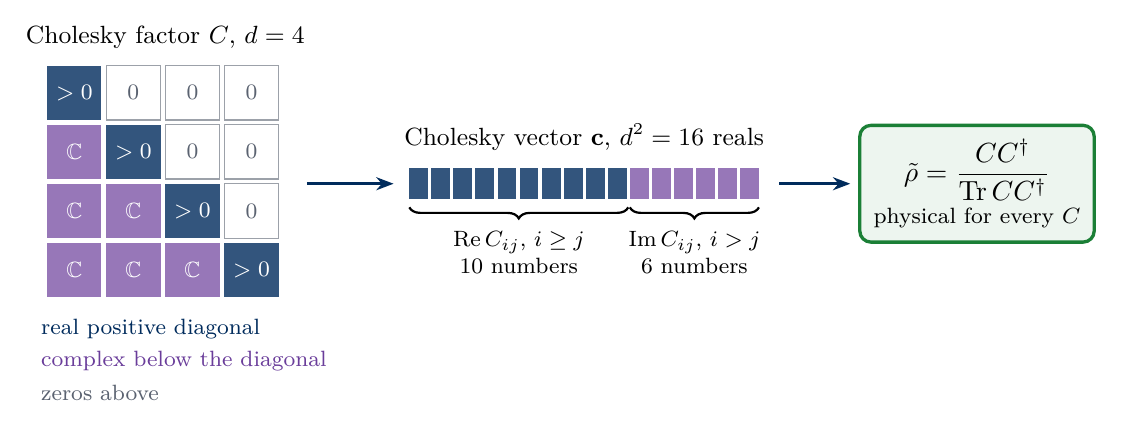

*The Cholesky factor of a two-qubit state has a real positive diagonal, complex entries below it and zeros above it. Its 16 free real numbers form the vector $\mathbf c$, and every factor $C$ defines a physical state through equation (10).*

Let $\mathbf c_{\boldsymbol\theta}$ be the normalised output vector of the network with parameters $\boldsymbol\theta$ and $\mathbf c_{\rm target}$ the vector of the true state. Training minimises their squared distance, averaged over a batch of $N_b$ training states,
$$\mathcal L(\boldsymbol\theta)=\frac1{N_b}\sum_{m=1}^{N_b}\big\|\mathbf c_{\boldsymbol\theta}(\tilde C_m)-\mathbf c_{{\rm target},m}\big\|^2 . \tag{12}$$
Here $\tilde C_m$ is the factor of the estimate of training state $m$, and the output is normalised to $\|\mathbf c_{\boldsymbol\theta}\|=1$, which is $\mathrm{Tr}\,CC^\dagger=1$.

The squared distance of the Cholesky vectors of two states, each of unit length, is at least the squared Bures distance $D_B^2=2-2\sqrt F$ between the states, where $F$ is their fidelity (6). The loss (12) is therefore an upper bound on the mean squared Bures distance between the network output and the true state, and a small distance guarantees a high fidelity, $F\ge(1-\|\mathbf c_1-\mathbf c_2\|^2/2)^2$, whenever this squared distance is at most two. The bound requires factors of unit trace, which is why the loss (12) is evaluated on the normalised network output. Apart from this normalisation it holds for any factors, so it applies also when the output $C$ of the network has negative or complex diagonal entries. The code checks the bound on 600 random pairs of states.

### Derivation of the bound (optional reading)

The derivation uses the polar decomposition, which writes every square matrix as a positive semidefinite matrix times a unitary, and the trace norm $\mathrm{Tr}\sqrt{K^\dagger K}$ of a matrix $K$, the sum of its singular values. Let $\hat\rho=C_1C_1^\dagger$ and $\hat\sigma=C_2C_2^\dagger$ be two states written with arbitrary square factors $C_1$ and $C_2$. The polar decomposition gives $C_1=\sqrt{\hat\rho}\,\hat V$ and $C_2=\sqrt{\hat\sigma}\,\hat W$ with unitaries $\hat V$ and $\hat W$, so $\mathrm{Tr}\,C_1C_2^\dagger=\mathrm{Tr}\big(\sqrt{\hat\sigma}\sqrt{\hat\rho}\,\hat V\hat W^\dagger\big)$. For any matrix $K$ the modulus of $\mathrm{Tr}(K\hat U)$ over all unitaries $\hat U$ is at most the trace norm $\mathrm{Tr}\sqrt{K^\dagger K}$, and for $K=\sqrt{\hat\sigma}\sqrt{\hat\rho}$ the trace norm is $\mathrm{Tr}\sqrt{\sqrt{\hat\rho}\,\hat\sigma\sqrt{\hat\rho}}=\sqrt F$ by equation (6). Hence [9]
$$\mathrm{Re}\,\mathrm{Tr}\,C_1C_2^\dagger\le\big|\mathrm{Tr}\,C_1C_2^\dagger\big|\le\sqrt{F(\hat\rho,\hat\sigma)} , \tag{13}$$
with equality for the best choice of $\hat V\hat W^\dagger$, which is Uhlmann's form of the fidelity [3]. Expanding the squared distance of the factors and using $\mathrm{Tr}\,C_1C_1^\dagger=\mathrm{Tr}\,C_2C_2^\dagger=1$ gives
$$\|C_1-C_2\|^2=\mathrm{Tr}\big[(C_1-C_2)(C_1-C_2)^\dagger\big]=2-2\,\mathrm{Re}\,\mathrm{Tr}\,C_1C_2^\dagger\;\ge\;2-2\sqrt{F(\hat\rho,\hat\sigma)}=D_B^2(\hat\rho,\hat\sigma) , \tag{14}$$
where $D_B^2$ is the squared Bures distance. For Cholesky factors $\|C_1-C_2\|^2$ is the sum of the squared differences of the real and imaginary parts of all entries, which is $\|\mathbf c_1-\mathbf c_2\|^2$, and this gives the statement above.

Let the network output $C$ have a different trace, $\mathrm{Tr}\,CC^\dagger=n^2\neq1$, and let the target factor $C_2$ have unit trace. Equation (13) applied to $C/n$ gives $\mathrm{Re}\,\mathrm{Tr}\,CC_2^\dagger\le n\sqrt F$, where $F$ is the fidelity of the states (10) of the two factors, so $\|C-C_2\|^2\ge n^2+1-2n\sqrt F\ge1-F\ge\tfrac12D_B^2$. The second step takes the smallest value over $n$, reached at $n=\sqrt F$, and the third uses $1-F=(1-\sqrt F)(1+\sqrt F)\ge1-\sqrt F$. The distance of unnormalised factors therefore bounds only half of the squared Bures distance.

In [7]:
EPS = 1e-6     # regularisation of rank-deficient states before the Cholesky factorisation

def cholesky_factor(rho):
    # equation (9): lower-triangular C with real positive diagonal, C C^dagger = (rho + EPS 1)/(1 + d EPS)
    d = rho.shape[-1]
    return np.linalg.cholesky(rho + EPS * np.eye(d)) / np.sqrt(1 + d * EPS)

def cholesky_vector(C):
    # equation (11): Re of the lower triangle with the diagonal, Im of the strict lower triangle -> d^2 reals
    d = C.shape[-1]
    lo, st = np.tril_indices(d), np.tril_indices(d, -1)
    return np.concatenate([C[:, lo[0], lo[1]].real, C[:, st[0], st[1]].imag], 1)

def factor_to_state(C):
    r = C @ C.conj().transpose(0, 2, 1)                  # equation (10): physical for every C
    return r / np.trace(r, axis1=1, axis2=2).real[:, None, None]

def squared_bures(rho, sigma):
    return 2 - 2 * np.sqrt(np.clip(fidelity(rho, sigma), 0, 1))

# check of equation (14) on random pairs of states
C_a = cholesky_factor(np.concatenate([haar_pure(300, d2), hs_mixed(300, d2)]))
C_b = cholesky_factor(np.concatenate([hs_mixed(300, d2), haar_pure(300, d2)]))
lhs = squared_bures(factor_to_state(C_a), factor_to_state(C_b))
rhs = np.sum((cholesky_vector(C_a) - cholesky_vector(C_b)) ** 2, 1)
assert np.allclose(rhs, np.sum(np.abs(C_a - C_b) ** 2, (1, 2)))
assert np.all(lhs <= rhs + 1e-9)
print(f"Cholesky vector of d = {d2}: {cholesky_vector(C_a).shape[1]} real numbers; equation (14) holds for all "
      f"{len(lhs)} pairs, mean ratio D_B^2 / |c_a - c_b|^2 = {np.mean(lhs / rhs):.2f}")
NUMBERS.update(BoundRatio=f"{np.mean(lhs / rhs):.2f}")

Cholesky vector of d = 4: 16 real numbers; equation (14) holds for all 600 pairs, mean ratio D_B^2 / |c_a - c_b|^2 = 0.67


The bound holds for all pairs, and for these unrelated states the squared Bures distance is on average about two thirds of the squared distance of the Cholesky vectors. Minimising the loss (12) therefore pushes the fidelity towards one.

## 7. Training and test data

In the protocol of the sketch a simulated device provides the counts, and a standard estimator turns them into an estimate $\tilde\rho$. The network corrects the Cholesky factor $\tilde C$ of this estimate, and the loss (12) compares the output with the factor $C_{\rm target}$ of the true state, known only for the training states.

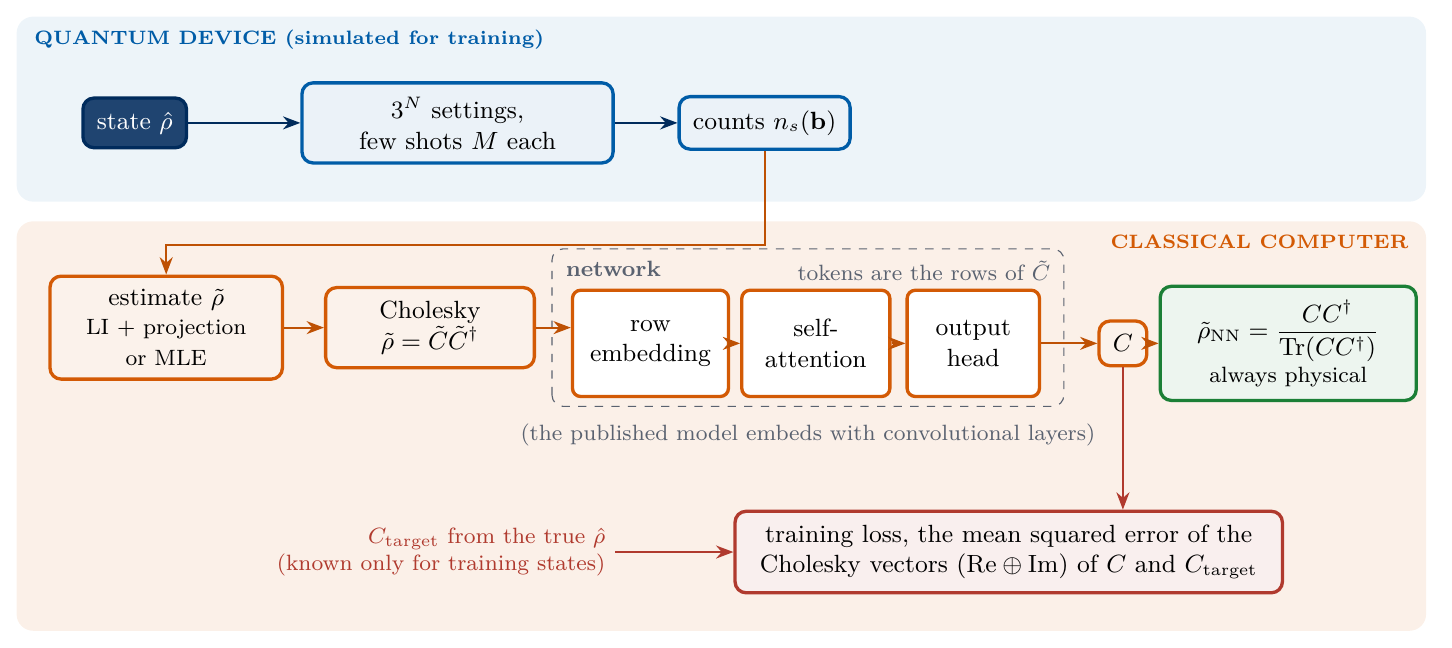

*Neural-network tomography as in Ref. [1]. Counts from the $3^N$ settings give an estimate $\tilde\rho$ (linear inversion with projection, or MLE). The network maps its Cholesky factor $\tilde C$ to a factor $C$, which always defines a physical state $\tilde\rho_{\rm NN}$. Training compares $C$ with the factor $C_{\rm target}$ of the true state. Ref. [1] embeds the input with convolutional layers, whereas our networks embed the rows of $\tilde C$ directly.*

For every shot number $M\in\{10,100,1000\}$ we build a training set of 5000 states of two qubits, half Haar-random pure and half Hilbert–Schmidt mixed. Each state is measured once in all nine settings with $M$ shots per setting. The network input is the Cholesky factor $\tilde C$ of the projected linear-inversion estimate $\tilde\rho_{\rm proj}$, and the target is the factor $C_{\rm target}$ of the true state. Separate test sets of 500 pure and 500 mixed states, drawn independently, are used only for evaluation. A separate network is trained for every $M$, since the size of the correction depends on the noise level.

In [8]:
def make_data(rho, N, M, PI, DUAL):
    # input: Cholesky factor of the projected LI estimate; target: Cholesky factor of the true state rho
    f = measure(rho, PI, N, M)
    rho_li = linear_inversion(f, DUAL)
    rho_proj = project_physical(rho_li)
    return dict(rho=rho, f=f, rho_proj=rho_proj, unphysical=float(np.mean(np.linalg.eigvalsh(rho_li)[:, 0] < -1e-12)),
                C_in=cholesky_factor(rho_proj), C_target=cholesky_factor(rho))

N_TRAIN, N_TEST = 5000, 500
t_data = time.perf_counter()
DATA2 = {}
for M in M_LIST:
    train_states = np.concatenate([haar_pure(N_TRAIN // 2, d2), hs_mixed(N_TRAIN // 2, d2)])
    DATA2[M] = dict(train=make_data(train_states, N2, M, PI2, DUAL2),
                    test_pure=make_data(haar_pure(N_TEST, d2), N2, M, PI2, DUAL2),
                    test_mixed=make_data(hs_mixed(N_TEST, d2), N2, M, PI2, DUAL2))
print(f"{len(M_LIST)} shot numbers x ({N_TRAIN} training + {2 * N_TEST} test states) in {time.perf_counter() - t_data:.1f} s")
NUMBERS.update(NTrain=f"{N_TRAIN}", NTest=f"{N_TEST}")

3 shot numbers x (5000 training + 1000 test states) in 0.4 s


## 8. Two networks

Both networks return the input factor plus a learned correction $\Delta_{\boldsymbol\theta}$,
$$C_{\boldsymbol\theta}=\tilde C+\Delta_{\boldsymbol\theta}(\tilde C) , \tag{15}$$
restricted to the entries that a Cholesky factor may occupy. The last layer of each network starts at zero, so the untrained network returns the projected estimate unchanged, and training only has to learn the deviation of the estimate from the true state.

The multilayer perceptron (MLP) treats the 16 numbers of the Cholesky vector (11) as one input vector. Two hidden layers of 80 units with the GELU activation [10], a smooth version of the rectifier, map it to a correction of the same length. The MLP receives no information on which entries belong together.

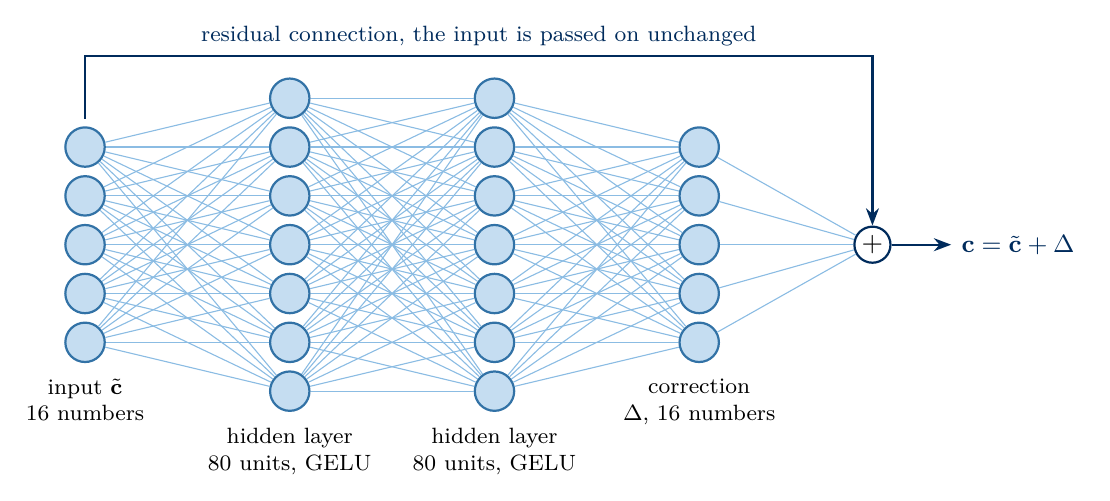

*The two-qubit MLP. The 16 numbers of $\tilde{\mathbf c}$ pass through two hidden layers of 80 units with GELU, and the output correction $\Delta$ is added to the input, equation (15).*

The second network uses the structure of the factor, in which an entry of the density matrix is the inner product of two rows,
$$\rho_{ij}=\sum_kC_{ik}C^*_{jk}=\mathbf r_i\cdot\mathbf r_j^* , \tag{16}$$
where $\mathbf r_i$ is row $i$ of $C$. Every coherence $\rho_{ij}$ couples two rows, so a correction of row $i$ depends on all other rows. We take the $d$ rows as the vectors that enter a self-attention layer [11]. Row $i$, written as the $2d$ real numbers $(\mathrm{Re}\,\mathbf r_i,\mathrm{Im}\,\mathbf r_i)$, is mapped by a trained matrix $W_E$ to
$$\mathbf x_i=W_E(\mathrm{Re}\,\mathbf r_i,\mathrm{Im}\,\mathbf r_i)+\mathbf e_i \tag{17}$$
of width $d_{\rm model}=32$, where the trained vector $\mathbf e_i$ marks the position of the row. The position matters, since row $i$ of a lower-triangular matrix has only $i+1$ nonzero entries.

Attention mixes the vectors with couplings that are computed from the vectors themselves, in three operations. The first compares all pairs of vectors with a trained rule. Two trained matrices $W_{\rm L}$ and $W_{\rm R}$ define the score
$$s_{ij}=(W_{\rm L}\mathbf x_i)\cdot(W_{\rm R}\mathbf x_j)=\mathbf x_i^{T}g\,\mathbf x_j,\qquad g=W_{\rm L}^{T}W_{\rm R} .$$
The matrix $g$ is a trained bilinear form, and for $g$ equal to the identity the score is the ordinary dot product. A large score marks row $j$ as relevant for the correction of row $i$. The second operation turns the scores of each $i$ into positive weights that sum to one, and the third averages the content of all vectors, selected by a third trained matrix $W_V$, with these weights,
$$a_{ij}=\frac{\exp\big(s_{ij}/\sqrt{d_h}\big)}{\sum_{j'}\exp\big(s_{ij'}/\sqrt{d_h}\big)},\qquad \mathbf y_i=\sum_ja_{ij}\,W_V\mathbf x_j , \tag{18}$$
where $d_h$ is the number of rows of $W_{\rm L}$ and $W_{\rm R}$, the head width. The weights are Boltzmann weights with energies $-s_{ij}$ and temperature $\sqrt{d_h}$, a normalisation called softmax. Training fixes the three matrices, which are then the same for every input, and every input fixes its own weights $a_{ij}$. For $W_{\rm L}=W_{\rm R}$ the form $g$ is symmetric and positive semidefinite, and the weights are Gaussian in the trained distance $d_g^2(\mathbf x_i,\mathbf x_j)=(\mathbf x_i-\mathbf x_j)^{T}g\,(\mathbf x_i-\mathbf x_j)$, times a factor that depends only on $j$. In the code the matrices $W_{\rm L}$, $W_{\rm R}$ and $W_V$ are the entries `query`, `key` and `value` of the parameter dictionary, the names used in Ref. [11].

We use four heads, four independent triples $W_{\rm L}$, $W_{\rm R}$, $W_V$ with $d_h=d_{\rm model}/4=8$ rows each, whose outputs are concatenated and mixed by one more matrix. The code stores the four matrices of each kind stacked in one $32\times32$ array and splits the result into four parts of width eight. The array `q` then holds $W_{\rm L}\mathbf x_i$ and `k` holds $W_{\rm R}\mathbf x_j$ for all heads, and the line that defines `scores` forms their dot products $s_{ij}$, so the matrix $g$ is never built explicitly. Each `dense` map also adds a trained offset.

The block follows the transformer layer of Ref. [11], which surrounds the three operations with layer normalisation and two additions. Layer normalisation [12] rescales each vector to zero mean and unit variance and then applies a trained gain and a trained shift, the entries `gain` and `shift` in the code. It keeps the scores of comparable size for all inputs, which helps to keep the weights (18) away from the limit in which a single row receives all the weight and the gradient vanishes. The vectors that enter the comparison are therefore the layer-normalised $\mathbf x_i$, the array `xn`. The output of the attention is added to the vector $\mathbf x_i$ itself, so the three operations only have to learn a change of the vector, as in equation (15). A two-layer network with a hidden layer of 64 units and GELU then acts on every vector separately, after a second layer normalisation, and transforms each row with the information collected from the other rows. Its output is added to the vector in the same way, which is the second addition. A third layer normalisation and a final linear map turn every vector back into a correction of its row.

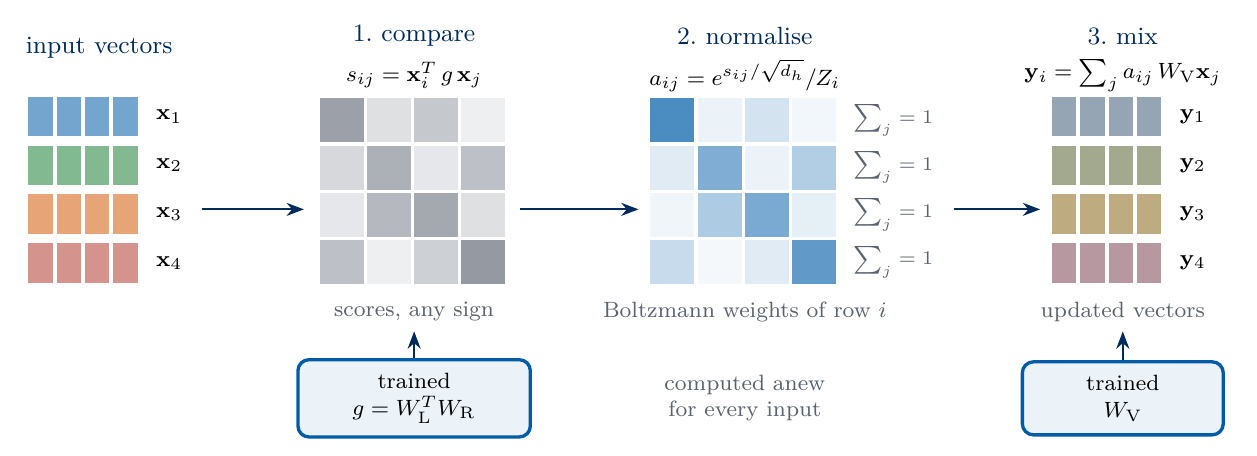

*Attention in three operations. The trained bilinear form $g$ compares all pairs of input vectors, the scores of each row are normalised to Boltzmann weights, and the output vectors are averages of the transformed inputs with these weights.*

The code stores a factor as the real array $X=[\mathrm{Re}\,C\,|\,\mathrm{Im}\,C]$ with $d$ rows and $2d$ columns, whose row $i$ is $(\mathrm{Re}\,\mathbf r_i,\mathrm{Im}\,\mathbf r_i)$. Its nonzero entries are the $d^2$ numbers of the Cholesky vector (11) in a different order, so the squared distance of two such arrays equals that of their Cholesky vectors, and the loss (12) is evaluated on these arrays.

The widths are chosen so that both networks have about 9000 parameters. Every layer is written out below with JAX arrays, and the parameters are stored in nested dictionaries and lists. The attention weights (18) are computed by broadcasting, which is faster on a CPU than many small matrix products.

In [9]:
def dense_init(rng_key, n_in, n_out, scale=1.0):
    # W has shape (n_in, n_out), so the map acts on the last axis of x from the right
    return dict(W=jax.random.normal(rng_key, (n_in, n_out)) * scale / np.sqrt(n_in), b=jnp.zeros(n_out))

def dense(p, x):
    return x @ p["W"] + p["b"]                                # (..., n_in) -> (..., n_out), with a trained offset b

def layer_norm(p, x):
    # zero mean and unit variance along the last axis, then a trained gain and a trained shift, each of shape (width,)
    mu = x.mean(-1, keepdims=True); var = x.var(-1, keepdims=True)
    return (x - mu) / jnp.sqrt(var + 1e-5) * p["gain"] + p["shift"]

def n_parameters(params):
    return sum(x.size for x in jax.tree_util.tree_leaves(params))

def rows_mask(d):
    # entries of the rows [Re C | Im C] that a Cholesky factor may occupy: Re on and below the diagonal, Im below it
    return np.concatenate([np.tril(np.ones((d, d))), np.tril(np.ones((d, d)), -1)], 1).astype(np.float32)

def to_rows(C):
    return np.concatenate([C.real, C.imag], -1).astype(np.float32)          # (batch, d, 2d)

def rows_to_factor(X):
    d = X.shape[1]
    return np.asarray(X[:, :, :d], np.float64) + 1j * np.asarray(X[:, :, d:], np.float64)

# ---- multilayer perceptron on the Cholesky vector ----
def mlp_init(rng_key, d, hidden):
    ks = jax.random.split(rng_key, 3)
    # the last layer starts at zero: the untrained network returns its input
    return [dense_init(ks[0], d * d, hidden), dense_init(ks[1], hidden, hidden), dense_init(ks[2], hidden, d * d, 0.0)]

def mlp_apply(params, X):
    d = X.shape[1]
    free = np.flatnonzero(rows_mask(d))                       # positions of the d^2 free entries of the factor inside X
    x = X.reshape(X.shape[0], -1)[:, free]                    # (B, d^2)     the numbers of the Cholesky vector, row by row
    h = jax.nn.gelu(dense(params[0], x))                      # (B, hidden)
    h = jax.nn.gelu(dense(params[1], h))                      # (B, hidden)
    y = x + dense(params[2], h)                               # (B, d^2)     equation (15)
    return jnp.zeros((X.shape[0], 2 * d * d)).at[:, free].set(y).reshape(X.shape)      # back to (B, d, 2d)

# ---- one self-attention block on the rows of the factor ----
# shapes: B = batch size, d = number of rows, H = number of heads, d_h = width / H, indices i and j label rows
def attention_init(rng_key, d, width, hidden):
    ks = jax.random.split(rng_key, 9)
    ln = lambda: dict(gain=jnp.ones(width), shift=jnp.zeros(width))
    # "query", "key" and "value" hold the matrices W_L, W_R and W_V of all heads, stacked along the output axis
    return dict(embed=dense_init(ks[0], 2 * d, width), position=0.1 * jax.random.normal(ks[1], (d, width)),
                ln1=ln(), query=dense_init(ks[2], width, width), key=dense_init(ks[3], width, width),
                value=dense_init(ks[4], width, width), mix=dense_init(ks[5], width, width),
                ln2=ln(), ff1=dense_init(ks[6], width, hidden), ff2=dense_init(ks[7], hidden, width),
                ln3=ln(), out=dense_init(ks[8], width, 2 * d, 0.0))

def attention_weights(params, X, heads):
    # vectors x_i of equation (17) and weights a_ij of equation (18) for every head
    B, d, _ = X.shape                                                         # X: (B, d, 2d), row i is [Re r_i | Im r_i]
    x = dense(params["embed"], X) + params["position"]                        # (B, d, width)   x_i = W_E row_i + offset + e_i, equation (17)
    xn = layer_norm(params["ln1"], x)                                         # (B, d, width)   layer-normalised x_i
    d_head = x.shape[-1] // heads                                             # d_h = width / H
    q = dense(params["query"], xn).reshape(B, d, heads, d_head)               # (B, i, H, d_h)  W_L x_i + offset, split into heads
    k = dense(params["key"], xn).reshape(B, d, heads, d_head)                 # (B, j, H, d_h)  W_R x_j + offset
    v = dense(params["value"], xn).reshape(B, d, heads, d_head)               # (B, j, H, d_h)  W_V x_j + offset
    scores = jnp.sum(q[:, :, None] * k[:, None, :], -1) / np.sqrt(d_head)     # (B, i, j, H)    compare: s_ij / sqrt(d_h)
    weights = jax.nn.softmax(scores, axis=2)                                  # (B, i, j, H)    normalise over j: a_ij
    return x, weights, v

def attention_apply(params, X, heads=4):
    B, d, _ = X.shape                                                         # X: (B, d, 2d)
    x, A, v = attention_weights(params, X, heads)                             # x: (B, d, width), A: (B, i, j, H), v: (B, j, H, d_h)
    y = jnp.sum(A[..., None] * v[:, None], axis=2).reshape(B, d, -1)          # (B, i, H, d_h) -> (B, d, width)  mix: y_i = sum_j a_ij W_V x_j, heads joined
    x = x + dense(params["mix"], y)                                           # (B, d, width)   heads mixed by one matrix, first addition
    h = jax.nn.gelu(dense(params["ff1"], layer_norm(params["ln2"], x)))       # (B, d, hidden)  two-layer network on every vector, first layer
    x = x + dense(params["ff2"], h)                                           # (B, d, width)   second layer, second addition
    correction = dense(params["out"], layer_norm(params["ln3"], x))           # (B, d, 2d)      back to a row [Re r_i | Im r_i]
    return (X + correction) * rows_mask(d)                                    # (B, d, 2d)      equation (15), allowed entries only

key, k_m, k_a = jax.random.split(key, 3)
print("MLP parameters:      ", n_parameters(mlp_init(k_m, d2, 80)))
print("attention parameters:", n_parameters(attention_init(k_a, d2, 32, 64)))

MLP parameters:       9136
attention parameters: 9288


## 9. Training with Adam

We minimise the loss (12) with Adam [13], a variant of gradient descent that scales the step of every parameter with running averages of its past gradients and of their squares. The update is written out in a few lines of the code, with the standard averaging constants of Ref. [13] and a step size that starts at $3\times10^{-3}$ and decreases to zero along a cosine. Each step uses a mini-batch of 250 training states, drawn without repetition from shuffled copies of the training set, and the gradient comes from `jax.grad` [14]. Every network is trained for 800 steps, which are 40 passes through the training set, inside one compiled `jax.lax.scan`, in which one call of the function `step` is one Adam step. This budget was fixed in advance for all networks and is short. After the training the cell evaluates the loss once on the complete training set and once on the test states, which the training never used. In class we train both networks for $M=100$, and Section 12 repeats the training for $M=10$ and $M=1000$. The training times printed below depend on the computer and its load.

M =  100, MLP      : loss 0.1276 -> 0.0640 in 1.0 s
          MLP      : final loss on all training states 0.0641, on the test states 0.0728
M =  100, attention: loss 0.1255 -> 0.0604 in 4.2 s
          attention: final loss on all training states 0.0607, on the test states 0.0704


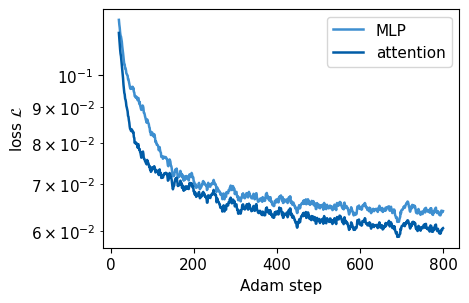

In [10]:
def normalised(Y):
    return Y / jnp.sqrt(jnp.sum(Y ** 2, axis=(1, 2), keepdims=True))         # Tr(C C^dagger) = 1

def loss_fn(params, apply, X_in, X_target):
    # equation (12)
    return jnp.mean(jnp.sum((normalised(apply(params, X_in)) - X_target) ** 2, axis=(1, 2)))

def train(params, apply, X_in, X_target, steps, batch, lr, seed):
    # Adam [13] with a cosine decay of the step size; mini-batches from shuffled copies of the training set
    n = X_in.shape[0]
    shuffle = np.random.default_rng(seed)
    idx = np.concatenate([shuffle.permutation(n) for _ in range(steps * batch // n + 1)])[:steps * batch]
    X_in, X_target = jnp.asarray(X_in), jnp.asarray(X_target)
    value_and_grad = jax.value_and_grad(loss_fn)

    @jax.jit
    def run(params, idx):
        def step(carry, inp):
            # one Adam step: carry = (parameters, running mean of the gradient, running mean of its square)
            p, m, v = carry
            t, batch_idx = inp                                                 # step number and the indices of one mini-batch
            L, grad = value_and_grad(p, apply, X_in[batch_idx], X_target[batch_idx])
            m = jax.tree_util.tree_map(lambda m_, g_: 0.9 * m_ + 0.1 * g_, m, grad)              # running mean of the gradient
            v = jax.tree_util.tree_map(lambda v_, g_: 0.999 * v_ + 0.001 * g_ ** 2, v, grad)     # and of its square
            eta = lr * 0.5 * (1 + jnp.cos(jnp.pi * t / steps))                 # step size on a cosine from lr to zero
            p = jax.tree_util.tree_map(lambda p_, m_, v_: p_ - eta * (m_ / (1 - 0.9 ** (t + 1)))
                                       / (jnp.sqrt(v_ / (1 - 0.999 ** (t + 1))) + 1e-8), p, m, v)
            return (p, m, v), L                                                # new carry, and the loss as the output of this step
        zeros = jax.tree_util.tree_map(jnp.zeros_like, params)
        # scan calls step once per row of (step numbers, mini-batch indices) and stacks the losses
        (p, _, _), history = jax.lax.scan(step, (params, zeros, zeros), (jnp.arange(steps), idx))
        return p, history
    params, history = run(params, jnp.asarray(idx.reshape(steps, batch)))
    return params, np.asarray(history)

def reconstruct(params, apply, C_in):
    return factor_to_state(rows_to_factor(apply(params, jnp.asarray(to_rows(C_in)))))     # equation (10)

STEPS2, BATCH, LR2 = 800, 250, 3e-3
M_CORE = 100
MODELS2 = {"MLP": (lambda k: mlp_init(k, d2, 80), mlp_apply),
           "attention": (lambda k: attention_init(k, d2, 32, 64), partial(attention_apply, heads=4))}
TRAINED2, HISTORY2, TRAIN_TIME2, FINAL_LOSS2 = {}, {}, {}, {}

def train_two_qubits(M):
    tr = DATA2[M]["train"]
    global key
    for name, (init, apply) in MODELS2.items():
        key, k_init = jax.random.split(key)
        t0 = time.perf_counter()
        TRAINED2[M, name], HISTORY2[M, name] = train(init(k_init), apply, to_rows(tr["C_in"]), to_rows(tr["C_target"]),
                                                     STEPS2, BATCH, LR2, seed=M)
        TRAIN_TIME2[M, name] = time.perf_counter() - t0
        print(f"M = {M:4d}, {name:9s}: loss {HISTORY2[M, name][:10].mean():.4f} -> {HISTORY2[M, name][-50:].mean():.4f}"
              f" in {TRAIN_TIME2[M, name]:.1f} s")
        # loss (12) of the trained network on the complete training set and on the test states (500 pure and 500 mixed)
        C_test_in = np.concatenate([DATA2[M]["test_pure"]["C_in"], DATA2[M]["test_mixed"]["C_in"]])
        C_test_target = np.concatenate([DATA2[M]["test_pure"]["C_target"], DATA2[M]["test_mixed"]["C_target"]])
        FINAL_LOSS2[M, name] = dict(train=float(loss_fn(TRAINED2[M, name], apply, jnp.asarray(to_rows(tr["C_in"])), jnp.asarray(to_rows(tr["C_target"])))),
                                    test=float(loss_fn(TRAINED2[M, name], apply, jnp.asarray(to_rows(C_test_in)), jnp.asarray(to_rows(C_test_target)))))
        print(f"          {name:9s}: final loss on all training states {FINAL_LOSS2[M, name]['train']:.4f}, on the test states {FINAL_LOSS2[M, name]['test']:.4f}")

train_two_qubits(M_CORE)
NUMBERS.update(StepsTwo=f"{STEPS2}", Batch=f"{BATCH}")

fig, ax = plt.subplots()
for name, c in (("MLP", COL["mlp"]), ("attention", COL["attn"])):
    smooth = np.convolve(HISTORY2[M_CORE, name], np.ones(20) / 20, mode="valid")
    ax.semilogy(np.arange(len(smooth)) + 20, smooth, color=c, lw=1.8, label=name)
ax.set_xlabel("Adam step"); ax.set_ylabel(r"loss $\mathcal{L}$")
ax.legend(loc="upper right")
save(fig, "fig_lab076_training"); plt.show()

The figure shows the loss (12) on the mini-batches at $M=100$, averaged over 20 steps, for both networks. The loss starts at the error of the projected estimate, since the untrained networks return their input, and decreases by about a factor of two during training. The loss flattens towards the end of the training, where the step size goes to zero. A floor above zero is expected, because the same estimate can come from many different true states and no map from the estimate can return all of them. The short budget may leave the final loss above this floor. On the complete training set the trained networks reach a loss of $0.064$ (MLP) and $0.061$ (attention), and on the test states $0.073$ and $0.070$. The loss on new states is thus about 15 per cent larger than on the training states, which indicates that the networks have begun to fit the particular records of the training set. The two networks follow nearly the same curves.

## 10. Fidelities of the four estimators

We evaluate four estimates on the same test records, the projected linear inversion $\tilde\rho_{\rm proj}$, MLE from equation (7), and the outputs $\tilde\rho_{\rm NN}$ of both networks. The linear-inversion estimate itself has no fidelity when it is unphysical, so the table reports the fraction of unphysical estimates in its place. The figure shows the mean infidelity $1-\bar F$ at $M=100$ with error bars of one standard error of the mean over 500 test states. Every network result of this notebook comes from one training run and one data set, so the standard errors describe the scatter over the test states only.

evaluation incl. MLE: 3.8 s

mean fidelity on 500 test states per row
    M test states LI unphys.  LI+proj      MLE      MLP attention
  100        pure       1.00   0.9652   0.9771   0.9862    0.9876
  100       mixed       0.65   0.9566   0.9600   0.9564    0.9602
largest standard error of a mean fidelity: 0.0011


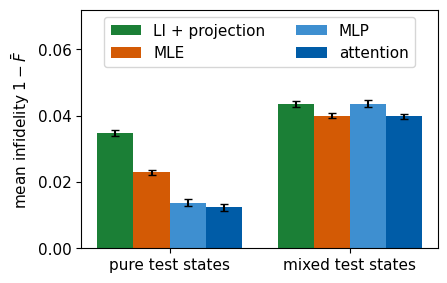

In [11]:
RESULTS2 = {}
STYLE = {"proj": ("LI + projection", COL["proj"], "o"), "mle": ("MLE", COL["mle"], "s"),
         "MLP": ("MLP", COL["mlp"], "^"), "attention": ("attention", COL["attn"], "D")}

def evaluate_two_qubits(M):
    for part in ("test_pure", "test_mixed"):
        s = DATA2[M][part]
        r = dict(proj=fidelity(s["rho"], s["rho_proj"]), mle=fidelity(s["rho"], mle(s["f"], PI2, N2)))
        for name, (_, apply) in MODELS2.items():
            r[name] = fidelity(s["rho"], reconstruct(TRAINED2[M, name], apply, s["C_in"]))
        r["unphysical"] = s["unphysical"]
        RESULTS2[M, part] = r

def print_table(M_values):
    print("mean fidelity on 500 test states per row")
    print(f"{'M':>5s} {'test states':>11s} {'LI unphys.':>10s} {'LI+proj':>8s} {'MLE':>8s} {'MLP':>8s} {'attention':>9s}")
    for M in M_values:
        for part in ("test_pure", "test_mixed"):
            r = RESULTS2[M, part]
            print(f"{M:5d} {part[5:]:>11s} {r['unphysical']:10.2f} " + " ".join(f"{np.mean(r[k]):8.4f}" for k in ("proj", "mle", "MLP"))
                  + f" {np.mean(r['attention']):9.4f}")
    sem = max(np.std(RESULTS2[M, p][k]) / np.sqrt(N_TEST) for M in M_values for p in ("test_pure", "test_mixed")
              for k in ("proj", "mle", "MLP", "attention"))
    print(f"largest standard error of a mean fidelity: {sem:.4f}")

t_eval = time.perf_counter()
evaluate_two_qubits(M_CORE)
print(f"evaluation incl. MLE: {time.perf_counter() - t_eval:.1f} s\n")
print_table([M_CORE])

fig, ax = plt.subplots()
xpos = np.arange(2)
for j, (k, (name, c, mk)) in enumerate(STYLE.items()):
    infid = [1 - np.mean(RESULTS2[M_CORE, p][k]) for p in ("test_pure", "test_mixed")]
    err = [np.std(RESULTS2[M_CORE, p][k]) / np.sqrt(N_TEST) for p in ("test_pure", "test_mixed")]
    ax.bar(xpos + (j - 1.5) * 0.2, infid, 0.2, yerr=err, color=c, capsize=3, label=name)
ax.set_xticks(xpos, ["pure test states", "mixed test states"])
ax.set_ylabel(r"mean infidelity $1-\bar F$")
ax.set_ylim(0, 0.072)
ax.legend(loc="upper center", ncol=2)
save(fig, "fig_lab076_fidelity_m100"); plt.show()

For pure test states both networks lower the mean infidelity of the projected estimate from about $3.5\times10^{-2}$ to about $1.3\times10^{-2}$, well below the $2.3\times10^{-2}$ of MLE. For mixed test states the mean fidelities of all four estimates differ by less than $0.005$. This pattern agrees with Section 5. The bias is largest for pure states, and an estimator of a full-rank state far from the boundary has little bias that a network could remove [1]. The MLP and the attention network reach nearly the same fidelities, so for two qubits, with only four rows, the structure of the attention block brings no clear advantage at this training budget.

### Convergence of the maximum-likelihood baseline

The comparison with MLE is meaningful only if the iteration (7) has reached the maximum of the likelihood. We repeat it for the first 100 pure and the first 100 mixed test records at $M=100$ with 4000 iterations and compare with a reference, the same iteration written in NumPy double precision with 1000 and with 4000 iterations. The cell prints the mean fidelities and the largest change of a single fidelity, and it asserts that the mean fidelity used in the table agrees with the reference within $10^{-3}$.

In [12]:
def rhor_reference(f, PI, N, iterations, sigma=None):
    # equation (7) in NumPy double precision, the reference for the single-precision JAX iteration;
    # sigma continues an earlier run, the default starts from the maximally mixed state
    d = 2 ** N
    P = PI.reshape(len(PI), -1); PT = np.ascontiguousarray(PI.transpose(0, 2, 1).reshape(len(PI), -1).T)
    sigma = np.broadcast_to(np.eye(d, dtype=complex) / d, (len(f), d, d)).copy() if sigma is None else sigma.copy()
    for _ in range(iterations):
        p = (sigma.reshape(len(f), -1) @ PT).real                               # p_s(b|sigma) = Tr[sigma pi_{s,b}]
        R = ((f / np.maximum(p, 1e-300)) @ P).reshape(len(f), d, d) / 3 ** N
        sigma = R @ sigma @ R
        sigma /= np.trace(sigma, axis1=1, axis2=2).real[:, None, None]
    return sigma

MLE_CHECK = {}
def check_mle(M, n_sub):
    # mean MLE fidelity of the first n_sub test records: table value (float32, 1000 iterations) against longer and more precise runs
    for part in ("test_pure", "test_mixed"):
        s = DATA2[M][part]
        rho, f = s["rho"][:n_sub], s["f"][:n_sub]
        F = {"float32, 1000": RESULTS2[M, part]["mle"][:n_sub], "float32, 4000": fidelity(rho, mle(f, PI2, N2, 4000)),
             "float64, 1000": fidelity(rho, rhor_reference(f, PI2, N2, 1000)), "float64, 4000": fidelity(rho, rhor_reference(f, PI2, N2, 4000))}
        ref = F["float64, 4000"]
        MLE_CHECK[M, part] = dict(n=n_sub, mean={k: float(v.mean()) for k, v in F.items()},
                                  largest_single_change={k: float(np.abs(v - ref).max()) for k, v in F.items()})
        print(f"M = {M:4d}, {part[5:]:5s}, {n_sub} records: mean F " + ", ".join(f"{k} it.: {v.mean():.5f}" for k, v in F.items()))
        print(f"{'':27s}largest change of a single F against float64, 4000 it.: "
              + ", ".join(f"{k}: {np.abs(v - ref).max():.1e}" for k, v in F.items() if k != "float64, 4000"))
        # the table value agrees with the double-precision reference far below the differences discussed in the text
        assert abs(F["float32, 1000"].mean() - ref.mean()) < 1e-3
        assert abs(F["float64, 1000"].mean() - ref.mean()) < 5e-4

t_check = time.perf_counter()
check_mle(M_CORE, 100)
print(f"convergence check: {time.perf_counter() - t_check:.1f} s")

M =  100, pure , 100 records: mean F float32, 1000 it.: 0.97747, float32, 4000 it.: 0.97769, float64, 1000 it.: 0.97704, float64, 4000 it.: 0.97704
                           largest change of a single F against float64, 4000 it.: float32, 1000: 1.1e-03, float32, 4000: 2.1e-03, float64, 1000: 1.4e-05
M =  100, mixed, 100 records: mean F float32, 1000 it.: 0.96025, float32, 4000 it.: 0.96024, float64, 1000 it.: 0.96015, float64, 4000 it.: 0.96005
                           largest change of a single F against float64, 4000 it.: float32, 1000: 2.6e-03, float32, 4000: 1.6e-03, float64, 1000: 2.6e-03
convergence check: 2.3 s


In double precision the mean fidelity of the pure records is the same after 1000 and after 4000 iterations to five digits, and that of the mixed records changes by $10^{-4}$. The single-precision iteration used for the tables lies above this reference by $4\times10^{-4}$ for the pure records and by $2\times10^{-4}$ for the mixed ones, and for pure records its mean keeps rising when it is iterated further, which is an effect of rounding in `float32`. Single fidelities differ from the reference by up to $3\times10^{-3}$. These differences are smaller than the standard errors of the mean fidelities, about $10^{-3}$, and much smaller than the gap of about $0.01$ between the networks and MLE for pure states. The rounding raises the fidelity of MLE, so it does not favour the networks in the comparison. Section 12 repeats the check on the complete test sets for all three shot numbers.

## 11. Depolarised test states

A network trained on one family of states may fail on states of another family. To test this, we prepare Haar-random pure states mixed with white noise by the depolarising channel,
$$\hat\rho_p=(1-p)\,|\psi\rangle\langle\psi|+p\,\frac{\hat I}{d} , \tag{19}$$
for $p$ between $0$ and $0.5$. Such states have one large eigenvalue and $d-1$ equal small ones, a spectrum that neither training family has, since Haar states have one nonzero eigenvalue and Hilbert–Schmidt states have unequal eigenvalues spread around $1/d$. We reconstruct 300 states for every $p$ with $M=100$ and apply the networks trained for $M=100$ without any change. The cell prints the mean fidelities with their standard errors over the 300 states. All four estimators see the same records, so it also prints the mean gain of each network over each standard estimator, with the standard error of this paired difference, which is smaller than the error of a difference of two independent means.

p = 0.0: purity 1.000 | LI + projection 0.9650  MLE 0.9765  MLP 0.9834  attention 0.9852
p = 0.1: purity 0.858 | LI + projection 0.9463  MLE 0.9536  MLP 0.9563  attention 0.9449
p = 0.2: purity 0.730 | LI + projection 0.9335  MLE 0.9395  MLP 0.9554  attention 0.9493
p = 0.3: purity 0.617 | LI + projection 0.9367  MLE 0.9403  MLP 0.9574  attention 0.9593
p = 0.5: purity 0.438 | LI + projection 0.9546  MLE 0.9559  MLP 0.9575  attention 0.9588

standard errors of the mean fidelities over 300 states
p = 0.0: LI + projection 0.0013  MLE 0.0009  MLP 0.0025  attention 0.0023
p = 0.1: LI + projection 0.0009  MLE 0.0007  MLP 0.0014  attention 0.0015
p = 0.2: LI + projection 0.0012  MLE 0.0011  MLP 0.0018  attention 0.0019
p = 0.3: LI + projection 0.0017  MLE 0.0017  MLP 0.0010  attention 0.0010
p = 0.5: LI + projection 0.0018  MLE 0.0018  MLP 0.0009  attention 0.0010

mean gain in fidelity on the same records, with its standard error, in units of 0.001
MLP       - LI + projection: p=0.0: +18.4 

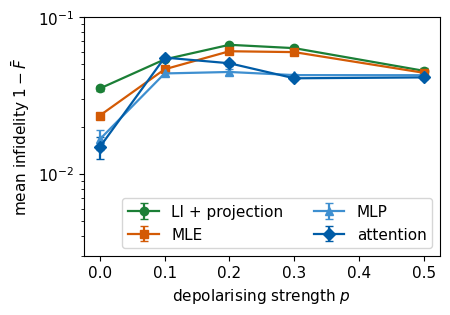

In [13]:
M_OOD, P_DEPOL, N_OOD = 100, (0.0, 0.1, 0.2, 0.3, 0.5), 300
OOD = {k: [] for k in STYLE}                    # mean fidelity for every p
OOD_SEM = {k: [] for k in STYLE}                # standard error of that mean over the N_OOD states
OOD_GAIN = {(net, ref): [] for net in MODELS2 for ref in ("proj", "mle")}     # paired difference F_network - F_standard: (mean, standard error)
for p in P_DEPOL:
    rho_p = (1 - p) * haar_pure(N_OOD, d2) + p * np.eye(d2) / d2           # equation (19)
    s = make_data(rho_p, N2, M_OOD, PI2, DUAL2)
    F_p = dict(proj=fidelity(rho_p, s["rho_proj"]), mle=fidelity(rho_p, mle(s["f"], PI2, N2)))
    for name, (_, apply) in MODELS2.items():
        F_p[name] = fidelity(rho_p, reconstruct(TRAINED2[M_OOD, name], apply, s["C_in"]))
    for k in STYLE:
        OOD[k].append(F_p[k].mean()); OOD_SEM[k].append(F_p[k].std() / np.sqrt(N_OOD))
    for net, ref in OOD_GAIN:
        gain = F_p[net] - F_p[ref]                                          # same records for both estimators
        OOD_GAIN[net, ref].append((gain.mean(), gain.std() / np.sqrt(N_OOD)))
    print(f"p = {p:.1f}: purity {purity(rho_p).mean():.3f} | " + "  ".join(f"{STYLE[k][0]} {OOD[k][-1]:.4f}" for k in STYLE))
print(f"\nstandard errors of the mean fidelities over {N_OOD} states")
for j, p in enumerate(P_DEPOL):
    print(f"p = {p:.1f}: " + "  ".join(f"{STYLE[k][0]} {OOD_SEM[k][j]:.4f}" for k in STYLE))
print("\nmean gain in fidelity on the same records, with its standard error, in units of 0.001")
for (net, ref), rows in OOD_GAIN.items():
    print(f"{net:9s} - {STYLE[ref][0]:15s}: " + "  ".join(f"p={p:.1f}: {1e3 * g:+5.1f} +- {1e3 * e:3.1f}" for p, (g, e) in zip(P_DEPOL, rows)))
fig, ax = plt.subplots()
for k, (name, c, mk) in STYLE.items():
    ax.errorbar(P_DEPOL, 1 - np.array(OOD[k]), yerr=OOD_SEM[k], color=c, marker=mk, lw=1.6, ms=6, capsize=3, label=name)
ax.set_yscale("log"); ax.set_ylim(3e-3, 1e-1)
ax.set_xlabel(r"depolarising strength $p$"); ax.set_ylabel(r"mean infidelity $1-\bar F$")
ax.legend(loc="lower right", ncol=2)
save(fig, "fig_lab076_depolarised"); plt.show()
NUMBERS.update(OodM=f"{M_OOD}", OodProjHalf=f"{100 * OOD['proj'][-1]:.1f}", OodAttnHalf=f"{100 * OOD['attention'][-1]:.1f}",
               OodMlpHalf=f"{100 * OOD['MLP'][-1]:.1f}", OodMleHalf=f"{100 * OOD['mle'][-1]:.1f}",
               OodProjPointThree=f"{100 * OOD['proj'][3]:.1f}", OodMlpPointThree=f"{100 * OOD['MLP'][3]:.1f}",
               OodAttnPointThree=f"{100 * OOD['attention'][3]:.1f}", OodMlePointThree=f"{100 * OOD['mle'][3]:.1f}")
NUMBERS.update(OodSemMax=f"{max(max(v) for v in OOD_SEM.values()):.4f}")
for (net, ref), rows in OOD_GAIN.items():
    for p, (g, e) in zip(P_DEPOL, rows):
        w = {0.0: "Zero", 0.1: "PointOne", 0.2: "PointTwo", 0.3: "PointThree", 0.5: "Half"}[p]
        tag = ("Mlp" if net == "MLP" else "Attn") + ("Proj" if ref == "proj" else "Mle") + w
        NUMBERS["OodGain" + tag] = f"{100 * g:.1f}"; NUMBERS["OodGainErr" + tag] = f"{100 * e:.1f}"
time_core = time.perf_counter() - started
print(f"runtime of Sections 1-11: {time_core:.1f} s")

The figure shows the mean infidelity against the depolarising strength, with error bars of one standard error over the 300 states. The standard errors of the mean fidelities lie between $0.001$ and $0.003$, and those of the paired gains between $0.001$ and $0.002$. At $p=0$, $0.2$ and $0.3$ both networks improve on the projected estimate and on MLE by between $0.007$ and $0.023$, about three standard errors or more, so the correction learned on pure and Hilbert–Schmidt states carries over to these partly mixed states. At $p=0.1$ the MLP gains $0.010$ on the projection, and its gain of $0.003$ on MLE is two standard errors. The attention network agrees with the projection within the error at this $p$ and lies below MLE by $0.009$, about six standard errors, so here a standard estimator is better than this network. At $p=0.5$, where the states are as mixed as typical Hilbert–Schmidt states, all gains are $0.004$ or smaller. Those over the projection amount to about three and four standard errors, and of those over MLE only the gain of the attention network, $0.003$, exceeds two standard errors. The gain over the projection is about $0.02$ at $p=0$, $0.2$ and $0.3$ and for the MLP it does not differ between these three values by more than its error. For the attention network it is larger at $p=0.3$ than at $p=0.2$. The infidelity of the projected estimate and of MLE first grows with $p$, because the small eigenvalues $p/d$ are of the size of the noise. It decreases again as the state approaches the maximally mixed state.

The core route ends here.

## 12. Other shot numbers

This section and the next one can be worked through at home, and this section takes about one minute. We train both two-qubit networks also for $M=10$ and $M=1000$, with the same data sets, architecture and training budget, and compare the four estimates at all three shot numbers. The last cell of the section repeats the convergence check of the maximum-likelihood baseline of Section 10 on all 500 records of every test set.

M =   10, MLP      : loss 0.4070 -> 0.2915 in 0.9 s
          MLP      : final loss on all training states 0.2913, on the test states 0.2968
M =   10, attention: loss 0.3950 -> 0.2846 in 3.9 s
          attention: final loss on all training states 0.2846, on the test states 0.2986
M = 1000, MLP      : loss 0.0352 -> 0.0110 in 1.0 s
          MLP      : final loss on all training states 0.0110, on the test states 0.0119
M = 1000, attention: loss 0.0411 -> 0.0100 in 4.4 s
          attention: final loss on all training states 0.0101, on the test states 0.0108

mean fidelity on 500 test states per row
    M test states LI unphys.  LI+proj      MLE      MLP attention
   10        pure       1.00   0.8782   0.9090   0.8953    0.8931
   10       mixed       0.99   0.7881   0.7957   0.8154    0.8152
  100        pure       1.00   0.9652   0.9771   0.9862    0.9876
  100       mixed       0.65   0.9566   0.9600   0.9564    0.9602
 1000        pure       1.00   0.9893   0.9930   0.9981    0.998

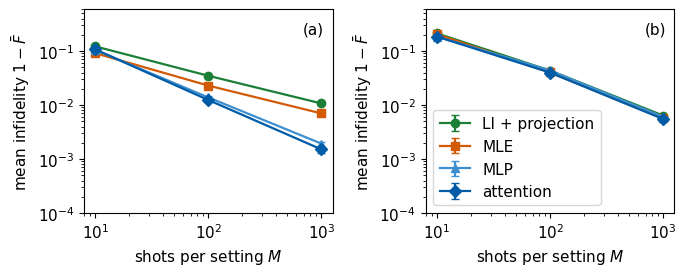

In [14]:
t_home = time.perf_counter()
for M in (10, 1000):
    train_two_qubits(M)
    evaluate_two_qubits(M)
print()
print_table(M_LIST)
for M, w in zip(M_LIST, ("Ten", "Hundred", "Thousand")):
    for part, k0 in (("pure", "Pure"), ("mixed", "Mixed")):
        for k, k1 in (("proj", "Proj"), ("mle", "Mle"), ("MLP", "Mlp"), ("attention", "Attn")):
            NUMBERS[k0 + k1 + w] = f"{100 * np.mean(RESULTS2[M, 'test_' + part][k]):.1f}"
        NUMBERS[k0 + "Unphysical" + w] = f"{RESULTS2[M, 'test_' + part]['unphysical']:.2f}"

def draw_fidelity(part, legend):
    def draw(ax, lab):
        for k, (name, c, mk) in STYLE.items():
            infid = [1 - np.mean(RESULTS2[M, part][k]) for M in M_LIST]
            err = [np.std(RESULTS2[M, part][k]) / np.sqrt(N_TEST) for M in M_LIST]
            ax.errorbar(M_LIST, infid, yerr=err, color=c, marker=mk, lw=1.6, ms=6, capsize=3, label=name)
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(1e-4, 0.6)
        ax.set_xlabel(r"shots per setting $M$"); ax.set_ylabel(r"mean infidelity $1-\bar F$")
        if lab:
            ax.text(0.88, 0.88, lab, transform=ax.transAxes)
        if legend or lab is None:
            ax.legend(loc="lower left")
    return draw
panels("fig_lab076_fidelity_two_qubits", [draw_fidelity("test_pure", False), draw_fidelity("test_mixed", True)])

Panel (a) shows pure test states and panel (b) mixed test states. For pure states both networks lower the infidelity of the projected estimate at every $M$, and at $M=100$ and $M=1000$ they also beat MLE. At $M=1000$ the infidelity drops from about $10^{-2}$ for the projection and $7\times10^{-3}$ for MLE to about $2\times10^{-3}$. At $M=10$, with 90 shots per state, MLE is the best of the four estimates for pure states, so a short training run does not guarantee an improvement over the best standard estimator. For mixed states the gain appears only at $M=10$, where both networks beat all standard estimators, while at $M=100$ and $M=1000$ the mean fidelities of all four estimates differ by less than $0.005$. The MLP and the attention network differ by at most $0.004$ in mean fidelity at every $M$.

In [15]:
# convergence of the MLE baseline on the complete test sets for all three shot numbers
t_check = time.perf_counter()
for M in M_LIST:
    check_mle(M, N_TEST)
mle_check_gap = max(abs(r["mean"]["float32, 1000"] - r["mean"]["float64, 4000"]) for r in MLE_CHECK.values())
print(f"largest difference of a mean fidelity between the table value and the float64 reference: {mle_check_gap:.1e}")
print(f"convergence check: {time.perf_counter() - t_check:.1f} s")
NUMBERS.update(MleCheckGap=f"{1e4 * mle_check_gap:.0f}")      # in units of 1e-4

M =   10, pure , 500 records: mean F float32, 1000 it.: 0.90899, float32, 4000 it.: 0.90913, float64, 1000 it.: 0.90865, float64, 4000 it.: 0.90865
                           largest change of a single F against float64, 4000 it.: float32, 1000: 1.3e-03, float32, 4000: 2.3e-03, float64, 1000: 8.7e-05
M =   10, mixed, 500 records: mean F float32, 1000 it.: 0.79566, float32, 4000 it.: 0.79571, float64, 1000 it.: 0.79548, float64, 4000 it.: 0.79541
                           largest change of a single F against float64, 4000 it.: float32, 1000: 7.7e-03, float32, 4000: 1.8e-03, float64, 1000: 7.7e-03
M =  100, pure , 500 records: mean F float32, 1000 it.: 0.97712, float32, 4000 it.: 0.97735, float64, 1000 it.: 0.97672, float64, 4000 it.: 0.97672
                           largest change of a single F against float64, 4000 it.: float32, 1000: 1.5e-03, float32, 4000: 2.4e-03, float64, 1000: 1.6e-04
M =  100, mixed, 500 records: mean F float32, 1000 it.: 0.95998, float32, 4000 it.: 0.95997, f

On the complete test sets the mean fidelity of the single-precision iteration lies above the double-precision reference in all six cases, by at most $4\times10^{-4}$. With the reference the MLE entries of the table for pure states would read $0.9086$, $0.9767$ and $0.9927$ in place of $0.9090$, $0.9771$ and $0.9930$, and those for mixed states $0.7954$, $0.9598$ and $0.9942$ in place of $0.7957$, $0.9600$ and $0.9943$. Every comparison of this section stays as stated. In double precision the mean fidelities after 1000 and 4000 iterations agree within about $10^{-4}$. For mixed states single fidelities still move by up to $0.008$ between 1000 and 4000 iterations, because the likelihood of a full-rank state changes little along some directions, while the mean moves by $10^{-4}$.

## 13. Four qubits and one-axis twisting

This section is work for home. It runs the same code for four qubits, $d=16$, with 81 settings and a Cholesky vector of 256 real numbers, and takes two to three minutes on a laptop CPU.

### 13.1 One-axis-twisted states and the quantum Fisher information

The test states come from one-axis twisting [15], the evolution of $N$ spins under the Hamiltonian $\hat{\mathcal H}=\hat J_z^2$, where $\hat J_a=\tfrac12\sum_{q=0}^{N-1}\hat\sigma_{a,q}$ is the collective spin along axis $a$. Since $\hat J_z^2=\tfrac14\sum_{q,q'}\hat Z_q\hat Z_{q'}$, this Hamiltonian couples every pair of spins with the same strength, an Ising interaction of infinite range. Starting from all spins along $x$,
$$|\Psi(t)\rangle=e^{-it\hat J_z^2}\,|+\rangle^{\otimes N} . \tag{20}$$
The Hamiltonian is diagonal in the computational basis, with eigenvalue $j_z^2$ on a bit string of magnetisation $j_z=(n_0-n_1)/2$, where $n_0$ and $n_1$ count the bits 0 and 1. Each amplitude therefore only acquires the phase $e^{-itj_z^2}$. The interaction makes the phase depend on $j_z$ nonlinearly, which correlates the spins and creates entanglement. For four qubits $e^{-i\pi j_z^2}=(-1)^{j_z}$ equals $\hat Z^{\otimes4}$ on every bit string, so $|\Psi(t+\pi)\rangle=\hat Z^{\otimes4}|\Psi(t)\rangle$. The state is therefore periodic with period $\pi$ up to the local unitary $\hat Z^{\otimes4}$, which changes neither the quantum Fisher information nor the entanglement, and at $t=\pi$ it is the product state $|-\rangle^{\otimes4}$. At $t=\pi/2$ the state is a superposition of all spins along $+x$ and all along $-x$, a cat state.

The entanglement of these states appears in their sensitivity to a collective rotation $e^{-i\phi\hat J_{\mathbf n}}$ about an axis given by the unit vector $\mathbf n$, with $\hat J_{\mathbf n}=\sum_an_a\hat J_a$. For a pure state the quantum Fisher information (QFI) of the rotation about a given axis $\mathbf n$ is $F_Q[\hat\rho,\hat J_{\mathbf n}]=4\,\mathrm{Var}(\hat J_{\mathbf n})$. It sets the smallest uncertainty of the angle $\phi$ that any measurement on $\mu$ copies of the state can reach, $\Delta\phi\ge1/\sqrt{\mu F_Q}$ [16,17]. For a state $\hat\rho=\sum_\alpha p_\alpha|\alpha\rangle\langle\alpha|$ with eigenvalues $p_\alpha$ and eigenvectors $|\alpha\rangle$ it reads [16]
$$F_Q[\hat\rho,\hat J_{\mathbf n}]=2\sum_{\alpha,\beta:\,p_\alpha+p_\beta>0}\frac{(p_\alpha-p_\beta)^2}{p_\alpha+p_\beta}\,\big|\langle\alpha|\hat J_{\mathbf n}|\beta\rangle\big|^2 , \tag{21}$$
which for a pure state equals four times the variance of $\hat J_{\mathbf n}$. Equation (21) is a quadratic form in $\mathbf n$, $F_Q=\mathbf n^{\mathsf T}\mathcal G\,\mathbf n$, with the real symmetric $3\times3$ matrix
$$\mathcal G_{ab}=2\sum_{\alpha,\beta:\,p_\alpha+p_\beta>0}\frac{(p_\alpha-p_\beta)^2}{p_\alpha+p_\beta}\,\mathrm{Re}\big(\langle\alpha|\hat J_a|\beta\rangle\langle\beta|\hat J_b|\alpha\rangle\big) , \tag{22}$$
so the largest QFI over all axes is the largest eigenvalue of $\mathcal G$. We use this maximum and write it $F_Q$.

A product state of $N$ spins has $F_Q\le N$, the shot-noise limit [18], and the coherent state $|+\rangle^{\otimes N}$ reaches it. Larger values require entanglement. A state is called $m$-producible if it can be prepared from groups of at most $m$ entangled spins, and then [19,20]
$$F_Q\le sm^2+r^2\le mN , \tag{23}$$
where $N=sm+r$ with $0\le r<m$. A measured QFI above the first bound excludes $m$-producible states and certifies that at least $m+1$ spins are entangled. For $N=4$ the first bound equals $4$, $8$, $10$ and $16$ for $m=1$, $2$, $3$ and $4$. With $m=3$ it gives $F_Q\le10$, so $F_Q/N>2.5$ certifies genuine four-spin entanglement. Ref. [1] uses the looser second form, $F_Q/N>m$, which for $m=3$ gives the threshold $F_Q/N>3$. We report both thresholds separately. The cat state reaches the maximum $F_Q=N^2$, which is $F_Q/N=4$.

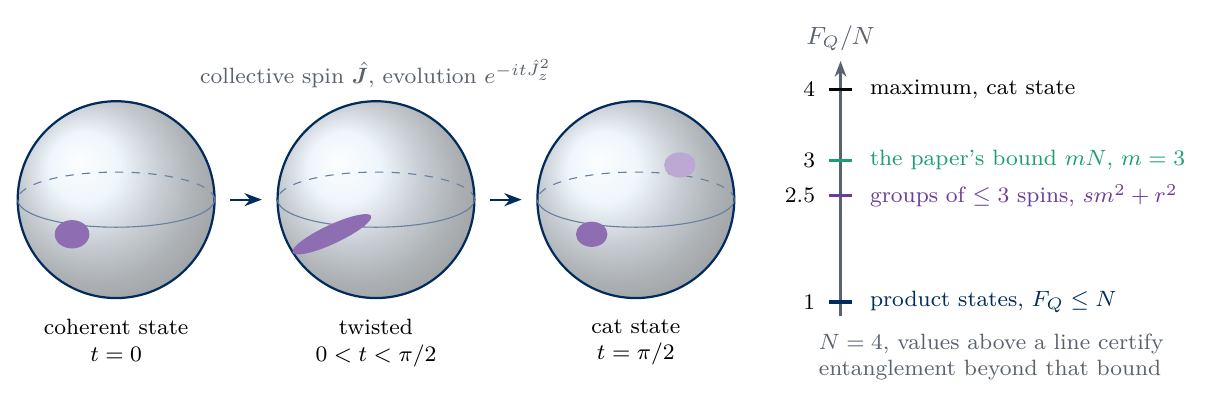

*One-axis twisting of four spins drawn on the sphere of the collective spin, from the coherent state through a twisted state to the cat state at $t=\pi/2$. The scale on the right marks $F_Q/N=1$ for product states, $2.5$ for the bound (23) with groups of at most three spins, $3$ for the looser bound of Ref. [1] and the maximum $4$.*

The cell checks the two limiting values.

In [16]:
N4 = 4; d4 = 2 ** N4
bits4 = (np.arange(d4)[:, None] >> (N4 - 1 - np.arange(N4))) & 1        # b_q of every basis state
j_z = (N4 - 2 * bits4.sum(1)) / 2                                         # eigenvalue j_z of J_z = (1/2) sum_q Z_q

def oat_state(t):
    # equation (20): e^{-i t J_z^2} |+>^N, diagonal in the computational basis
    return np.exp(-1j * t * j_z ** 2) / np.sqrt(d4)

J4 = {a: sum(kron_all([PAULI[a] / 2 if q == i else I2 for q in range(N4)]) for i in range(N4)) for a in "XYZ"}

def qfi_max(rho):
    # equations (21)-(22): largest F_Q over rotation axes = largest eigenvalue of the matrix G
    p, V = np.linalg.eigh(rho)
    Jk = np.stack([V.conj().transpose(0, 2, 1) @ J4[a] @ V for a in "XYZ"], 1)     # (batch, 3, d, d) in the eigenbasis
    s = p[:, :, None] + p[:, None, :]
    w = np.where(s > 1e-10, 2 * (p[:, :, None] - p[:, None, :]) ** 2 / np.where(s > 1e-10, s, 1), 0)
    G_qfi = np.einsum("bkl,bakl,bclk->bac", w, Jk, Jk).real
    return np.linalg.eigvalsh(G_qfi)[:, -1]

checks = qfi_max(np.array([np.outer(oat_state(t), oat_state(t).conj()) for t in (0.0, np.pi / 2)]))
print(f"F_Q/N: coherent state |+>^4 {checks[0] / N4:.3f}, OAT state at t = pi/2 {checks[1] / N4:.3f}")
assert abs(checks[0] - N4) < 1e-9 and abs(checks[1] - N4 ** 2) < 1e-9

F_Q/N: coherent state |+>^4 1.000, OAT state at t = pi/2 4.000


### 13.2 Training on Haar-random states

As in Ref. [1], the network is trained only on Haar-random pure states and never sees a one-axis-twisted state. We use $M=10$ shots per setting, which gives 810 shots per state, a budget at which the projected estimate has a fidelity of about $0.8$. The training set has 5000 states. The attention network has vectors of width $d_{\rm model}=64$, four heads and a hidden layer of 192 units per vector, about 47 000 parameters, and is trained for 1500 Adam steps with a starting step size of $2\times10^{-3}$. The test set contains 500 new Haar states and the one-axis-twisted states at 60 equally spaced times in $(0,\pi)$, each measured in three independent records. As a second standard baseline we compute the maximum-likelihood estimate (7) of the one-axis-twisted records, with 600 iterations of the double-precision function of Section 10. Double precision avoids the rounding drift of the single-precision iteration found there, and the cell of Section 13.3 compares the two on every sixth record. With 1296 projectors of size $16\times16$ this iteration is the slowest standard estimator of the notebook, so we compute it for the 180 one-axis-twisted records only.

In [17]:
t_four = time.perf_counter()
PI4, DUAL4 = pauli_measurement(N4)
M4, STEPS4, LR4 = 10, 1500, 2e-3
DATA4 = dict(train=make_data(haar_pure(N_TRAIN, d4), N4, M4, PI4, DUAL4),
             test_haar=make_data(haar_pure(N_TEST, d4), N4, M4, PI4, DUAL4))
T_OAT, REPEATS = np.linspace(0, np.pi, 60, endpoint=False) + np.pi / 120, 3
psi_oat = np.array([oat_state(t) for t in T_OAT for _ in range(REPEATS)])
DATA4["test_oat"] = make_data(np.einsum("bi,bj->bij", psi_oat, psi_oat.conj()), N4, M4, PI4, DUAL4)
print(f"N = {N4}: {3 ** N4} settings x {M4} shots = {3 ** N4 * M4} shots per state; Cholesky vector of {d4 ** 2} reals;"
      f" data in {time.perf_counter() - t_four:.1f} s")

key, k4 = jax.random.split(key)
apply4 = partial(attention_apply, heads=4)
params4 = attention_init(k4, d4, 64, 192)
print("attention parameters:", n_parameters(params4))
t0 = time.perf_counter()
params4, history4 = train(params4, apply4, to_rows(DATA4["train"]["C_in"]), to_rows(DATA4["train"]["C_target"]),
                          STEPS4, BATCH, LR4, seed=4)
time_train4 = time.perf_counter() - t0
print(f"loss {history4[:10].mean():.4f} -> {history4[-50:].mean():.4f} after {STEPS4} steps in {time_train4:.1f} s")

N = 4: 81 settings x 10 shots = 810 shots per state; Cholesky vector of 256 reals; data in 2.8 s
attention parameters: 47072
loss 0.4678 -> 0.1428 after 1500 steps in 80.2 s


### 13.3 Fidelity and entanglement of the reconstructed states

For every test record we compare the projected estimate and the network output with the true state, and for the one-axis-twisted records also the maximum-likelihood estimate. We evaluate the largest QFI (22) of the true state and of every reconstruction. A threshold of the bound (23) is misleading when a reconstruction lies above it while the true state lies below, so the cell also counts these records and the records in which a reconstruction has a larger QFI than the true state.

haar : mean fidelity LI+projection 0.785 +- 0.046, network 0.909 +- 0.091 (mean +- standard deviation)
oat  : mean fidelity LI+projection 0.786 +- 0.039, network 0.915 +- 0.036 (mean +- standard deviation)
haar : network fidelity below 0.7 in 0.030 of the records, below the projected estimate in 0.050, smallest value 0.056
oat  : mean fidelity MLE 0.918 +- 0.038 (600 iterations, float64, 19.1 s)
       MLE between 300 and 600 iterations: mean F changes by 2.2e-05, a single F by at most 2.7e-04, F_Q/N by at most 2.8e-03
       float32 iteration on 30 records: mean F 0.9174, float64 on the same records 0.9166
oat  : standard errors of the mean fidelities: proj 0.0029, mle 0.0028, nn 0.0027
oat  : network - MLE, mean difference of the fidelities -0.0036 +- 0.0036 (standard error); network above MLE at 35 of 60 times
       within 0.1 pi of t = 0, pi/2, pi (24 times): mean difference -0.038, network above MLE at 6; elsewhere (36 times): +0.020, network above MLE at 29
F_Q/N target: max 4.0

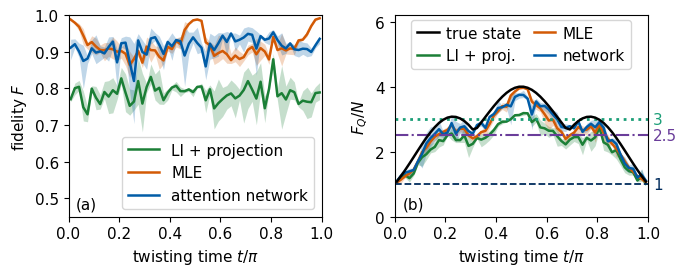

In [18]:
R4 = {}
for part in ("test_haar", "test_oat"):
    s = DATA4[part]
    rho_nn = reconstruct(params4, apply4, s["C_in"])
    R4[part] = dict(proj=fidelity(s["rho"], s["rho_proj"]), nn=fidelity(s["rho"], rho_nn), purity_nn=purity(rho_nn),
                    qfi_target=qfi_max(s["rho"]) / N4, qfi_proj=qfi_max(s["rho_proj"]) / N4, qfi_nn=qfi_max(rho_nn) / N4)
    print(f"{part[5:]:5s}: mean fidelity LI+projection {R4[part]['proj'].mean():.3f} +- {R4[part]['proj'].std():.3f},"
          f" network {R4[part]['nn'].mean():.3f} +- {R4[part]['nn'].std():.3f} (mean +- standard deviation)")
h, o = R4["test_haar"], R4["test_oat"]
print(f"haar : network fidelity below 0.7 in {np.mean(h['nn'] < 0.7):.3f} of the records, below the projected estimate in"
      f" {np.mean(h['nn'] < h['proj']):.3f}, smallest value {h['nn'].min():.3f}")

# second standard baseline for the one-axis-twisted records: maximum likelihood, equation (7)
# in double precision (rhor_reference of Section 10), ITER_MLE4 iterations in two halves
ITER_MLE4 = 600
t_mle4 = time.perf_counter()
f_oat, rho_oat = DATA4["test_oat"]["f"], DATA4["test_oat"]["rho"]
rho_mle4_half = rhor_reference(f_oat, PI4, N4, ITER_MLE4 // 2)
rho_mle4 = rhor_reference(f_oat, PI4, N4, ITER_MLE4 // 2, sigma=rho_mle4_half)       # continued to ITER_MLE4 iterations
o["mle"] = fidelity(rho_oat, rho_mle4); o["qfi_mle"] = qfi_max(rho_mle4) / N4
time_mle4 = time.perf_counter() - t_mle4
print(f"oat  : mean fidelity MLE {o['mle'].mean():.3f} +- {o['mle'].std():.3f} ({ITER_MLE4} iterations, float64, {time_mle4:.1f} s)")
# convergence: change over the second half of the iterations, and the single-precision JAX iteration on every sixth record
F_half4 = fidelity(rho_oat, rho_mle4_half)
sub4 = np.arange(0, len(f_oat), 6)
F_f32 = fidelity(rho_oat[sub4], mle(f_oat[sub4], PI4, N4, ITER_MLE4))
mle4_check = dict(mean_fidelity_change_second_half=float(abs(o["mle"].mean() - F_half4.mean())),
                  largest_single_change_second_half=float(np.abs(o["mle"] - F_half4).max()),
                  largest_qfi_per_spin_change_second_half=float(np.abs(o["qfi_mle"] - qfi_max(rho_mle4_half) / N4).max()),
                  float32_records=len(sub4), float32_minus_float64_mean_fidelity=float(F_f32.mean() - o["mle"][sub4].mean()))
print(f"       MLE between {ITER_MLE4 // 2} and {ITER_MLE4} iterations: mean F changes by {mle4_check['mean_fidelity_change_second_half']:.1e},"
      f" a single F by at most {mle4_check['largest_single_change_second_half']:.1e}, F_Q/N by at most {mle4_check['largest_qfi_per_spin_change_second_half']:.1e}")
print(f"       float32 iteration on {len(sub4)} records: mean F {F_f32.mean():.4f}, float64 on the same records {o['mle'][sub4].mean():.4f}")
assert mle4_check["mean_fidelity_change_second_half"] < 5e-4
sem4 = {k: float(o[k].std() / np.sqrt(len(o[k]))) for k in ("proj", "mle", "nn")}
print("oat  : standard errors of the mean fidelities: " + ", ".join(f"{k} {v:.4f}" for k, v in sem4.items()))
gain4 = o["nn"] - o["mle"]                                               # same records for both estimators
nT = len(T_OAT)
gain4_t = gain4.reshape(nT, REPEATS).mean(1)
near4 = (T_OAT / np.pi < 0.1) | (T_OAT / np.pi > 0.9) | (np.abs(T_OAT / np.pi - 0.5) < 0.1)      # within 0.1 pi of t = 0, pi/2, pi
gain4_stats = dict(mean=float(gain4.mean()), sem=float(gain4.std() / np.sqrt(len(gain4))), times_network_above=int((gain4_t > 0).sum()),
                   near_times=int(near4.sum()), near_mean=float(gain4_t[near4].mean()), near_network_above=int((gain4_t[near4] > 0).sum()),
                   far_times=int((~near4).sum()), far_mean=float(gain4_t[~near4].mean()), far_network_above=int((gain4_t[~near4] > 0).sum()))
print(f"oat  : network - MLE, mean difference of the fidelities {gain4_stats['mean']:+.4f} +- {gain4_stats['sem']:.4f} (standard error);"
      f" network above MLE at {gain4_stats['times_network_above']} of {nT} times")
print(f"       within 0.1 pi of t = 0, pi/2, pi ({gain4_stats['near_times']} times): mean difference {gain4_stats['near_mean']:+.3f}, network above MLE at"
      f" {gain4_stats['near_network_above']}; elsewhere ({gain4_stats['far_times']} times): {gain4_stats['far_mean']:+.3f}, network above MLE at {gain4_stats['far_network_above']}")

qfi_frac = {}
for name in ("target", "proj", "mle", "nn"):
    q = o["qfi_" + name]
    qfi_frac[name] = dict(above_1=float(np.mean(q > 1)), above_2_5=float(np.mean(q > 2.5)), above_3=float(np.mean(q > 3)), max=float(q.max()))
    print(f"F_Q/N {name:6s}: max {q.max():.2f}; fraction of records above 1: {np.mean(q > 1):.2f},"
          f" above 2.5: {np.mean(q > 2.5):.2f}, above 3: {np.mean(q > 3):.2f}")
# records in which a reconstruction lies above a threshold while the true value lies below it, and records with F_Q above the true F_Q
qfi_false = {}
for name in ("proj", "mle", "nn"):
    q = o["qfi_" + name]
    qfi_false[name] = dict(above_2_5_true_below=float(np.mean((q > 2.5) & (o["qfi_target"] <= 2.5))),
                           above_3_true_below=float(np.mean((q > 3) & (o["qfi_target"] <= 3))), above_true=float(np.mean(q > o["qfi_target"])))
    print(f"F_Q/N {name:6s}: above 2.5 with the true value below in {qfi_false[name]['above_2_5_true_below']:.3f} of the records,"
          f" above 3 with the true value below in {qfi_false[name]['above_3_true_below']:.3f}, above the true value in {qfi_false[name]['above_true']:.3f}")
q_true = o["qfi_target"].reshape(nT, REPEATS)[:, 0]
for name in ("mle", "nn"):
    over = o["qfi_" + name].reshape(nT, REPEATS).mean(1) > q_true
    print(f"mean F_Q/N of {name} above the true value at {over.sum()} of {nT} times, t/pi = " + ", ".join(f"{t:.3f}" for t in T_OAT[over] / np.pi))
time_four = time.perf_counter() - t_four
time_home = time.perf_counter() - t_home
print(f"runtime of Section 13: {time_four:.1f} s, of Sections 12-13: {time_home:.1f} s")
NUMBERS.update(MFour=f"{M4}", StepsFour=f"{STEPS4}", ParamsFour=f"{n_parameters(params4)}",
               HaarProjFour=f"{100 * R4['test_haar']['proj'].mean():.1f}", HaarNnFour=f"{100 * R4['test_haar']['nn'].mean():.1f}",
               OatProjFour=f"{100 * o['proj'].mean():.1f}", OatNnFour=f"{100 * o['nn'].mean():.1f}",
               OatProjStdFour=f"{100 * o['proj'].std():.1f}", OatNnStdFour=f"{100 * o['nn'].std():.1f}",
               OatMleFour=f"{100 * o['mle'].mean():.1f}", OatMleStdFour=f"{100 * o['mle'].std():.1f}", IterMleFour=f"{ITER_MLE4}",
               QfiMaxMle=f"{qfi_frac['mle']['max']:.2f}", QfiAboveThreeMle=f"{qfi_frac['mle']['above_3']:.2f}",
               QfiAboveTwoFiveMle=f"{qfi_frac['mle']['above_2_5']:.2f}",
               QfiFalseTwoFiveProj=f"{qfi_false['proj']['above_2_5_true_below']:.3f}", QfiFalseTwoFiveMle=f"{qfi_false['mle']['above_2_5_true_below']:.3f}",
               QfiFalseTwoFiveNn=f"{qfi_false['nn']['above_2_5_true_below']:.3f}", QfiFalseThreeProj=f"{qfi_false['proj']['above_3_true_below']:.3f}",
               QfiFalseThreeMle=f"{qfi_false['mle']['above_3_true_below']:.3f}", QfiFalseThreeNn=f"{qfi_false['nn']['above_3_true_below']:.3f}",
               QfiAboveTrueProj=f"{qfi_false['proj']['above_true']:.2f}", QfiAboveTrueMle=f"{qfi_false['mle']['above_true']:.2f}",
               QfiAboveTrueNn=f"{qfi_false['nn']['above_true']:.2f}", HaarNnBelowProjFour=f"{np.mean(h['nn'] < h['proj']):.2f}",
               QfiMaxProj=f"{qfi_frac['proj']['max']:.2f}", QfiMaxNn=f"{qfi_frac['nn']['max']:.2f}",
               QfiAboveThreeTarget=f"{qfi_frac['target']['above_3']:.2f}", QfiAboveThreeProj=f"{qfi_frac['proj']['above_3']:.2f}",
               QfiAboveThreeNn=f"{qfi_frac['nn']['above_3']:.2f}", QfiAboveTwoFiveTarget=f"{qfi_frac['target']['above_2_5']:.2f}",
               QfiAboveTwoFiveProj=f"{qfi_frac['proj']['above_2_5']:.2f}", QfiAboveTwoFiveNn=f"{qfi_frac['nn']['above_2_5']:.2f}")

EST4 = (("proj", "LI + projection", COL["proj"]), ("mle", "MLE", COL["mle"]), ("nn", "attention network", COL["attn"]))

def draw_oat_fidelity(ax, lab):
    for k, name, c in EST4:
        F = o[k].reshape(nT, REPEATS)
        ax.plot(T_OAT / np.pi, F.mean(1), color=c, lw=1.8, label=name)
        ax.fill_between(T_OAT / np.pi, F.min(1), F.max(1), color=c, alpha=0.25, lw=0)
    ax.set_xlim(0, 1); ax.set_ylim(0.45, 1.0)
    ax.set_xlabel(r"twisting time $t/\pi$"); ax.set_ylabel(r"fidelity $F$")
    ax.legend(loc="lower right")
    if lab:
        ax.text(0.03, 0.04, lab, transform=ax.transAxes)

def draw_oat_qfi(ax, lab):
    # lines: mean of three records; bands: smallest to largest; colours as in panel (a), short names to fit the panel
    short = {"LI + projection": "LI + proj.", "attention network": "network"}
    ax.plot(T_OAT / np.pi, q_true, color=COL["truth"], lw=1.8, label="true state", zorder=5)
    for k, name, c in EST4:
        q = o["qfi_" + k].reshape(nT, REPEATS)
        ax.plot(T_OAT / np.pi, q.mean(1), color=c, lw=1.8, label=short.get(name, name))
        ax.fill_between(T_OAT / np.pi, q.min(1), q.max(1), color=c, alpha=0.25, lw=0)
    # thresholds of the bound (23), labelled at the right edge: product states, four-spin entanglement, looser bound of Ref. [1]
    for y, c, ls, lw in ((1, COL["navy"], "--", 1.3), (2.5, COL["purple"], "-.", 1.5), (3, COL["teal"], ":", 2.0)):
        ax.axhline(y, color=c, ls=ls, lw=lw)
        ax.text(1.02, y, f"{y:g}", transform=ax.get_yaxis_transform(), color=c, va="center", ha="left")
    ax.set_xlim(0, 1); ax.set_ylim(0, 6.2)
    ax.set_xlabel(r"twisting time $t/\pi$"); ax.set_ylabel(r"$F_Q/N$")
    ax.legend(loc="upper center", ncol=2, columnspacing=0.8, handlelength=1.4, handletextpad=0.5, borderaxespad=0.3)
    if lab:
        ax.text(0.03, 0.04, lab, transform=ax.transAxes)

panels("fig_lab076_oat_four_qubits", [draw_oat_fidelity, draw_oat_qfi])

Panel (a) shows the fidelity of the 60 one-axis-twisted states for the projected estimate (green), MLE (orange) and the network output (blue), with the line at the mean of three records and the band between the smallest and the largest. The network raises the mean fidelity from $0.786$ for the projected estimate to $0.915$, about the same gain as on the Haar test states, although it never saw a twisted state. MLE reaches $0.918$ on the same records. The mean difference between the network and MLE is $-0.004$ with a standard error of $0.004$, so the network equals the stronger standard estimator within the statistical error and does not improve on it. MLE is better near $t=0$, $\pi/2$ and $\pi$, where the state is the product state $|\pm\rangle^{\otimes4}$ or the cat state, by $0.04$ on average within $0.1\pi$ of these times. The network is better by $0.02$ on average elsewhere, at 29 of the remaining 36 times. The MLE values are converged, since the second half of the 600 iterations changes the mean fidelity by $2\times10^{-5}$, and the single-precision iteration would lie $8\times10^{-4}$ higher on the 30 records of the comparison.

On the Haar test states the fidelity of the network output has twice the spread of the projected estimate, $0.091$ against $0.046$. Its fidelity lies below $0.7$ in 3 per cent of the records and below that of the projected estimate in 5 per cent, with a smallest value of $0.06$. The learned correction therefore improves the mean while it fails on a few single records.

Panel (b) shows the largest QFI per spin of the true state (black) and of the three reconstructions in the colours of panel (a), again with lines at the mean of three records and bands between the smallest and the largest. The navy dashed, purple dash-dotted and teal dotted lines, labelled at the right edge, mark $F_Q/N=1$ (product states), $F_Q/N=2.5$ (genuine four-spin entanglement by the bound (23)) and $F_Q/N=3$ (the looser bound of Ref. [1]). The projected estimates lose much of the QFI of the true states, because their noise mixes the state and the factor $(p_\alpha-p_\beta)^2/(p_\alpha+p_\beta)$ in equation (21) penalises mixing. MLE and the network output both recover a large part of it. Of all records, the true states exceed $F_Q/N=2.5$ in 73 per cent and $F_Q/N=3$ in 43 per cent, the network output in 66 and 27 per cent, MLE in 59 and 22 per cent, and the projected estimate in 37 and 9 per cent, with a largest value of $3.22$.

Equation (23) certifies entanglement only if the reconstruction does not overestimate the QFI. The network output has a larger QFI than the true state in 16 per cent of the records, against 1 per cent for MLE and 2 per cent for the projected estimate. The mean network curve lies above the true curve at 7 of the 60 times, close to $t=0$ and $t=\pi$ and at the two dips of the true curve near $t=\pi/3$ and $2\pi/3$, whereas the mean MLE curve stays below the true curve at all times. For each of the two thresholds the network output lies above the threshold while the true state lies below it in one of the 180 records, and MLE and the projected estimate do so in none. Such false exceedances are rare in this test, but they occur, so a single value above a threshold is no proof. The network output is a learned estimate without an error bound. Its values above the thresholds therefore do not certify four-spin entanglement by themselves and need an independent check, for example on test states with known QFI.

## 14. Published results and related work

The figures of this section are published results of Ref. [1], shown without change and not produced by our simulation. The first comes from a pair of qutrits, which are three-level systems, so $d=9$. The pair is measured with one informationally complete measurement of 81 outcomes, a set of 81 positive operators that add up to the identity and fix the state, which Ref. [1] builds from random states by a construction called the square-root measurement. The test states are 1000 Hilbert–Schmidt states, and the quality is the mean squared Hilbert–Schmidt distance $\overline{D^2_{\rm HS}}=\overline{\mathrm{Tr}(\tilde\rho_{\rm NN}-\hat\rho)^2}$. Panel (a) plots it against $N_{\rm trial}$, the number of copies of the state that are measured, which decreases to the right. The estimators are linear inversion (LI, green circles), MLE (red squares) and the network applied to either of them (LI-NN, blue diamonds, and MLE-NN, orange crosses). Panel (b) multiplies $N_{\rm trial}$ by the number of training states $N_{\rm train}$ and compares with the network of Ref. [21] (violet triangles).

![Published result of Ref. [1], not our simulation, mean squared Hilbert-Schmidt distance against the number of measured copies for qutrit pairs](attachment:fig_lab076_published_d9_benchmark.png)

*Published result of Ref. [1], not our simulation. Mean squared Hilbert–Schmidt distance for $d=9$, averaged over 1000 target states, against the number of measured copies (a) and against copies times training states (b). The networks were trained with 5000 (LI-NN) and 2000 (MLE-NN) states.*

The network improves linear inversion at every budget, and the network applied to MLE improves on MLE for fewer than about $10^3$ copies, the regime of our classroom example. With many copies MLE remains the best estimator. In panel (b) the protocol of Ref. [1] reaches distances similar to those of Ref. [21] with about an order of magnitude fewer training states, where Ref. [21] used $8\times10^5$ states.

The second figure is the four-qubit test of Ref. [1]. A network trained only on Haar-random states with shot noise reconstructs one-axis-twisted states. In this test Ref. [1] models the shot noise as Gaussian noise on the Pauli expectation values $\mathrm{Tr}[\hat\rho\hat P]$, which by itself gives a fidelity of about $0.85$. It then depolarises the state with $p=0.3$, as in equation (19), and models a calibration error of the measurement by adding a fixed bias, with random values of order $10^{-4}$, to every Pauli expectation value. The two panels correspond to two random realisations of the calibration error. The curves show $F_Q/N$ (written QFI/L) against $t/\pi$ for the true states (violet), for linear inversion (green) and for the network (red), with the looser thresholds $F_Q/N=m$ of Ref. [1] as dotted lines, labelled by $k=m+1$, the number of entangled spins they indicate.

![Published result of Ref. [1], not our simulation, QFI per spin of one-axis-twisted four-qubit states reconstructed from noisy data](attachment:fig_lab076_published_oat_qfi.png)

*Published result of Ref. [1], not our simulation. Largest QFI per spin of 100 one-axis-twisted states of four qubits under depolarisation and calibration errors. Violet marks the true states, green linear inversion and red the network applied to linear inversion. Panels (a) and (b) show two realisations of the calibration error.*

In this test linear inversion reaches a mean fidelity of $75.4\%$, and the network raises it to $88.7\%$ and $91.0\%$ for the two realisations [1]. Linear inversion stays below $F_Q/N=3$ at all times and falls below the shot-noise limit near $t=0$ and $t=\pi$, whereas the network output crosses $F_Q/N=3$ near $t=\pi/2$, which Ref. [1] takes as evidence of entanglement of all four spins. Our classroom result of Section 13 shows the same trend relative to linear inversion with shot noise only and a smaller network. In our simulation maximum likelihood reaches the same mean fidelity as the network.

The networks of Sections 8 and 13 correct a complete estimate and therefore need its $d^2$ parameters, which limits them to a few qubits. In neural-network quantum-state tomography [22] a restricted Boltzmann machine represents the wave function itself, its parameters are trained to reproduce the measured bit strings, and the trained network yields expectation values and entanglement entropies by sampling. Such a network describes structured states, such as ground states of local Hamiltonians, of many more qubits than full tomography can handle. It assumes that the state belongs to the family the network represents. Ref. [21] trains a network that maps measured frequencies directly to a state, which removes the intermediate estimator and needs many more training states.

The last cell stores the numbers of Sections 2 to 13 as LaTeX macros and a JSON summary and prints the runtime.
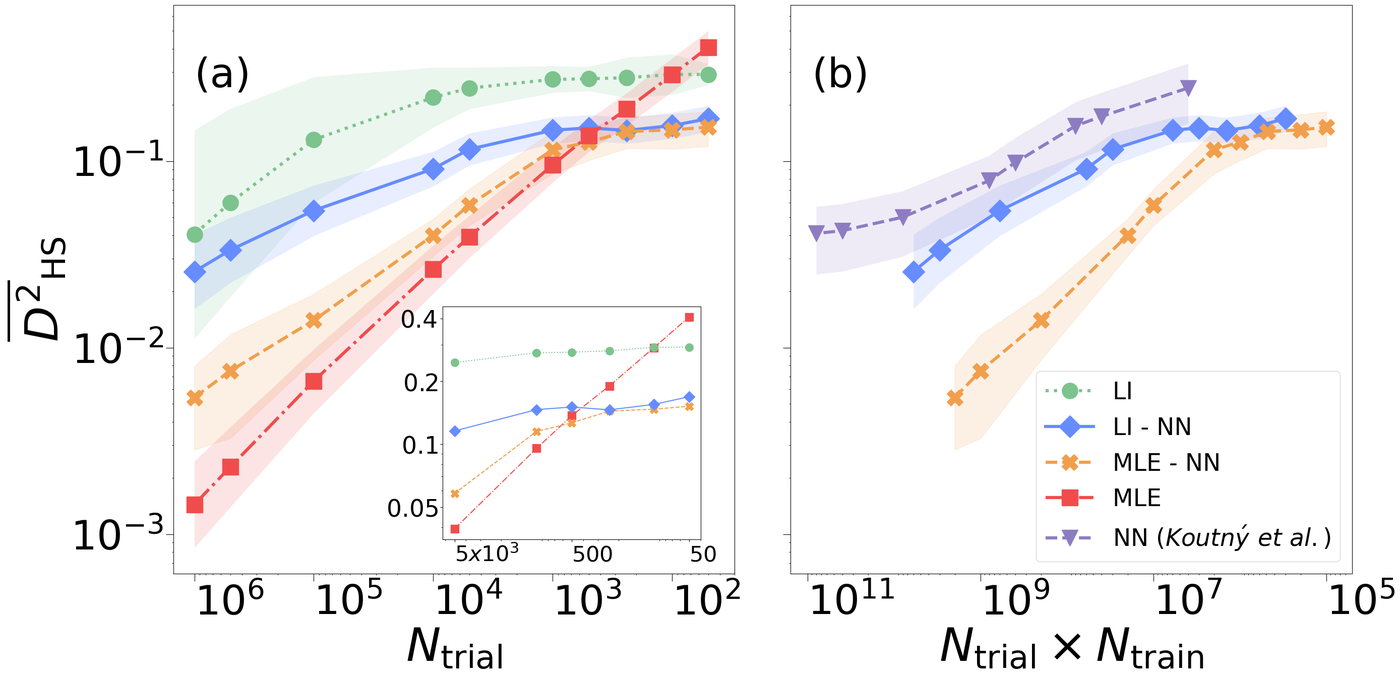
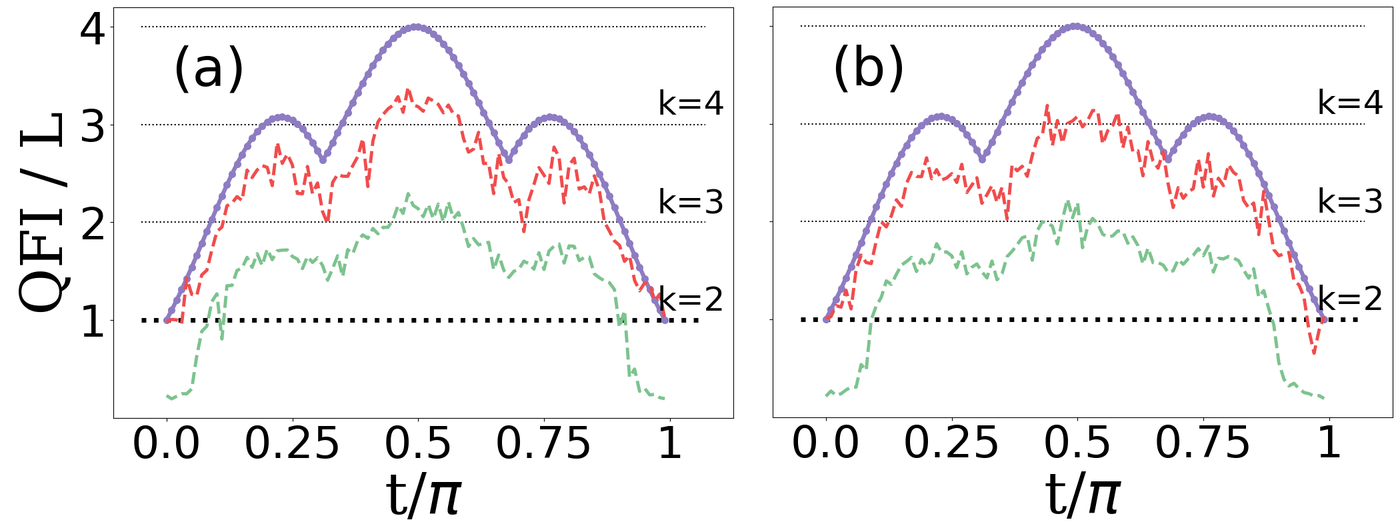

In [19]:
summary = dict(
    experiment="neural-network tomography: Pauli measurements (3^N settings, M shots each), LI + projection input, "
               "Cholesky representation, MLP and one self-attention block trained with Adam; JAX float32 on CPU",
    two_qubits=dict(M=list(M_LIST), n_train=N_TRAIN, n_test_per_family=N_TEST, steps=STEPS2, batch=BATCH, lr=LR2,
                    parameters={name: n_parameters(TRAINED2[M_LIST[0], name]) for name in MODELS2},
                    bias={str(M): dict(unphysical=bias[M]["unphysical"], purity_proj=float(bias[M]["purity_proj"].mean()))
                          for M in M_LIST},
                    bias_fixed_state=dict(M=M_FIXED, records=R_FIXED, estimators=bias_fixed),
                    bound_mean_ratio=float(np.mean(lhs / rhs)),
                    fidelity={f"M={M} {part[5:]}": {k: float(np.mean(v)) for k, v in r.items()} for (M, part), r in RESULTS2.items()},
                    final_loss={f"M={M} {name}": float(HISTORY2[M, name][-50:].mean()) for (M, name) in HISTORY2},
                    train_seconds={f"M={M} {name}": TRAIN_TIME2[M, name] for (M, name) in TRAIN_TIME2},
                    depolarised=dict(M=M_OOD, p=list(P_DEPOL), n_states=N_OOD, fidelity={k: [float(x) for x in v] for k, v in OOD.items()},
                                     fidelity_sem={k: [float(x) for x in v] for k, v in OOD_SEM.items()},
                                     paired_gain={f"{net} - {ref}": dict(mean=[float(g) for g, _ in rows], sem=[float(e) for _, e in rows])
                                                  for (net, ref), rows in OOD_GAIN.items()}),
                    fidelity_sem={f"M={M} {part[5:]}": {k: float(np.std(v) / np.sqrt(N_TEST)) for k, v in r.items() if k != "unphysical"}
                                  for (M, part), r in RESULTS2.items()},
                    final_loss_full_sets={f"M={M} {name}": v for (M, name), v in FINAL_LOSS2.items()},
                    mle_convergence={f"M={M} {part[5:]}": v for (M, part), v in MLE_CHECK.items()}),
    four_qubits=dict(M=M4, n_train=N_TRAIN, steps=STEPS4, lr=LR4, parameters=n_parameters(params4), train_seconds=time_train4,
                     final_loss=float(history4[-50:].mean()),
                     haar=dict(proj=float(R4["test_haar"]["proj"].mean()), nn=float(R4["test_haar"]["nn"].mean()),
                               proj_std=float(h["proj"].std()), nn_std=float(h["nn"].std()), nn_min=float(h["nn"].min()),
                               nn_below_0_7=float(np.mean(h["nn"] < 0.7)), nn_below_proj=float(np.mean(h["nn"] < h["proj"]))),
                     oat=dict(times=T_OAT.tolist(), repeats=REPEATS, fidelity_proj=o["proj"].tolist(), fidelity_nn=o["nn"].tolist(),
                              qfi_per_spin_target=o["qfi_target"].tolist(), qfi_per_spin_proj=o["qfi_proj"].tolist(),
                              qfi_per_spin_nn=o["qfi_nn"].tolist(), qfi_fractions=qfi_frac,
                              fidelity_mle=o["mle"].tolist(), qfi_per_spin_mle=o["qfi_mle"].tolist(), mle_iterations=ITER_MLE4,
                              mle_convergence=mle4_check, mle_seconds=time_mle4, fidelity_sem=sem4, network_minus_mle=gain4_stats,
                              qfi_false_exceedance=qfi_false)),
    published_ref1=dict(oat_fidelity_LI=75.4, oat_fidelity_NN=[88.7, 91.0], note="Ref. [1], not simulated here"),
    runtime_seconds=dict(core_sections_1_11=time_core, at_home_sections_12_13=time_home, four_qubits_section_13=time_four,
                         four_qubit_training=time_train4, total=time.perf_counter() - started))
NUMBERS.update(RuntimeCore=f"{time_core:.0f}", RuntimeHome=f"{time_home:.0f}", RuntimeFour=f"{time_four:.0f}")
(RES / "lab076_results.json").write_text(json.dumps(summary, indent=2))
with open(FIG / "nb_numbers_lab076.tex", "w") as f:
    for k_, v_ in NUMBERS.items():
        f.write(f"\\newcommand{{\\labseventysix{k_}}}{{{v_.strip()}}}\n")
print("numbers:", NUMBERS)
print(f"runtime: Sections 1-11 {time_core:.1f} s, Sections 12-13 {time_home:.1f} s, total {summary['runtime_seconds']['total']:.1f} s")

numbers: {'DemoMinEig': '-0.053', 'PurityHS': '0.47', 'PurityProjTen': '0.88', 'PurityProjHundred': '0.94', 'PurityProjThousand': '0.979', 'PureFracTen': '0.21', 'PureFracHundred': '0.11', 'PureFracThousand': '0.08', 'BiasFixedOverlapLi': '0.998', 'BiasFixedPurityLi': '0.996', 'BiasFixedDistanceLi': '0.006', 'BiasFixedStatErrorLi': '0.005', 'BiasFixedOverlapProj': '0.963', 'BiasFixedPurityProj': '0.929', 'BiasFixedDistanceProj': '0.043', 'BiasFixedStatErrorProj': '0.004', 'BiasFixedOverlapMle': '0.974', 'BiasFixedPurityMle': '0.948', 'BiasFixedDistanceMle': '0.033', 'BiasFixedStatErrorMle': '0.003', 'BiasFixedRecords': '1000', 'BiasFixedM': '100', 'BoundRatio': '0.67', 'NTrain': '5000', 'NTest': '500', 'StepsTwo': '800', 'Batch': '250', 'OodM': '100', 'OodProjHalf': '95.5', 'OodAttnHalf': '95.9', 'OodMlpHalf': '95.7', 'OodMleHalf': '95.6', 'OodProjPointThree': '93.7', 'OodMlpPointThree': '95.7', 'OodAttnPointThree': '95.9', 'OodMlePointThree': '94.0', 'OodSemMax': '0.0025', 'OodGainMlp

## 15. Exercises

1. Verify equation (3) for the state $|0\rangle$ and show that equation (4) with $N=2$ reproduces the Pauli expansion $\hat\rho=\tfrac14\sum_{P}\langle\hat P\rangle\hat P$, where each single-qubit expectation value is averaged over three settings.
2. Show that the projection (5) is the closest density matrix in the Hilbert–Schmidt norm for a diagonal $\tilde\rho_{\rm LI}$, by minimising $\sum_i(\lambda_i-\lambda_i')^2$ under the constraints $\lambda_i'\ge0$ and $\sum_i\lambda_i'=1$.
3. (Optional, uses the polar decomposition of Section 6.) Find two factors $C_1$ and $C_2$ of the same pair of states for which equation (14) is an equality, and explain why the Cholesky factors in general do not reach it.
4. Replace the input $\tilde\rho_{\rm proj}$ by the MLE estimate for $M=10$ and retrain both networks. Compare the fidelities for pure test states with those of Section 10 and with MLE alone. The function `make_data` builds the input from the projected estimate, so add an argument that selects the estimate from which `C_in` is computed.
5. Train the attention network for $M=100$ with 1000, 2000 and 5000 training states and plot the mean fidelity on pure test states against the size of the training set.
6. Plot the attention weights $a_{ij}$ of equation (18), averaged over the pure test states, for each of the four heads of the network trained with $M=100$, and describe which rows the first row reads from.
7. Train the two-qubit networks only on Hilbert–Schmidt states and evaluate them on pure test states. Explain the result with the bias of Section 5.
8. In Section 13, add depolarisation with $p=0.3$ to the one-axis-twisted test states without retraining, and compare the fidelity and the fraction of records with $F_Q/N>3$ with the noiseless case and with Ref. [1].

## 16. Summary

Linear inversion turns the frequencies of the $3^N$ Pauli settings into an unbiased estimate of the state, which is unphysical in almost every run for a pure state. Projecting it onto the physical states, or maximising the likelihood, gives a density matrix but introduces a bias. A pure state is an extreme point of the set of states, so any spread of physical estimates moves their mean towards mixed states. A neural network trained on pairs of an estimate and the true state learns a correction that depends on the estimate and removes part of this bias. Writing states through their Cholesky factors makes every network output a physical state, and the squared distance of the Cholesky vectors used as the loss bounds the squared Bures distance from above. For two qubits we trained an MLP and a single self-attention block over the rows of the factor, each with about 9000 parameters, for 800 Adam steps. Every network result comes from one training run and one data set. In this run both networks raise the fidelity of pure states above that of linear inversion with projection at all three shot numbers considered, and above maximum likelihood at 100 and 1000 shots per setting, while at 10 shots maximum likelihood is the best estimate. Mixed states far from the boundary gain little. On depolarised states, which are absent from the training set, both networks improve on the standard estimators by about three standard errors or more at three of the five depolarising strengths. At $p=0.1$ the attention network falls below maximum likelihood, and at $p=0.5$ the gains are $0.004$ or smaller. For four qubits an attention network trained only on Haar-random states raises the mean fidelity of one-axis-twisted states from 0.786 for the projected estimate to 0.915, which equals the 0.918 of maximum likelihood within the statistical error. The network and maximum likelihood both recover much of the quantum Fisher information that the projected estimate loses. The network output exceeds the thresholds $F_Q/N>2.5$ and $F_Q/N>3$ more often than both standard estimates, and it overestimates the quantum Fisher information in 16 per cent of the records, so a learned reconstruction without an error bound does not certify entanglement by itself. The maximum-likelihood baseline was checked against a longer iteration in double precision, which changes its mean fidelities by at most $4\times10^{-4}$. The gains over linear inversion are in line with the published results of Ref. [1] for data with additional depolarisation and calibration noise.

## References

[1] A. Macarone Palmieri, G. Müller-Rigat, A. K. Srivastava, M. Lewenstein, G. Rajchel-Mieldzioć and M. Płodzień, Enhancing quantum state tomography via resource-efficient attention-based neural networks, Phys. Rev. Research **6**, 033248 (2024), doi:[10.1103/PhysRevResearch.6.033248](https://doi.org/10.1103/PhysRevResearch.6.033248).

[2] J. A. Smolin, J. M. Gambetta and G. Smith, Efficient method for computing the maximum-likelihood quantum state from measurements with additive Gaussian noise, Phys. Rev. Lett. **108**, 070502 (2012), doi:[10.1103/PhysRevLett.108.070502](https://doi.org/10.1103/PhysRevLett.108.070502).

[3] A. Uhlmann, The "transition probability" in the state space of a *-algebra, Rep. Math. Phys. **9**, 273 (1976), doi:[10.1016/0034-4877(76)90060-4](https://doi.org/10.1016/0034-4877(76)90060-4).

[4] R. Jozsa, Fidelity for mixed quantum states, J. Mod. Opt. **41**, 2315 (1994), doi:[10.1080/09500349414552171](https://doi.org/10.1080/09500349414552171).

[5] Z. Hradil, Quantum-state estimation, Phys. Rev. A **55**, R1561 (1997), doi:[10.1103/PhysRevA.55.R1561](https://doi.org/10.1103/PhysRevA.55.R1561).

[6] J. Řeháček, Z. Hradil, E. Knill and A. I. Lvovsky, Diluted maximum-likelihood algorithm for quantum tomography, Phys. Rev. A **75**, 042108 (2007), doi:[10.1103/PhysRevA.75.042108](https://doi.org/10.1103/PhysRevA.75.042108).

[7] F. Mezzadri, How to generate random matrices from the classical compact groups, Notices Amer. Math. Soc. **54**, 592 (2007), [arxiv.org/abs/math-ph/0609050](https://arxiv.org/abs/math-ph/0609050).

[8] K. Życzkowski and H.-J. Sommers, Induced measures in the space of mixed quantum states, J. Phys. A **34**, 7111 (2001), doi:[10.1088/0305-4470/34/35/335](https://doi.org/10.1088/0305-4470/34/35/335).

[9] I. Bengtsson and K. Życzkowski, *Geometry of Quantum States: An Introduction to Quantum Entanglement*, 2nd ed. (Cambridge University Press, 2017), doi:[10.1017/9781139207010](https://doi.org/10.1017/9781139207010).

[10] D. Hendrycks and K. Gimpel, Gaussian error linear units (GELUs), arXiv:1606.08415 (2016), [arxiv.org/abs/1606.08415](https://arxiv.org/abs/1606.08415).

[11] A. Vaswani, N. Shazeer, N. Parmar, J. Uszkoreit, L. Jones, A. N. Gomez, Ł. Kaiser and I. Polosukhin, Attention is all you need, Advances in Neural Information Processing Systems **30** (2017), [arxiv.org/abs/1706.03762](https://arxiv.org/abs/1706.03762).

[12] J. L. Ba, J. R. Kiros and G. E. Hinton, Layer normalization, arXiv:1607.06450 (2016), [arxiv.org/abs/1607.06450](https://arxiv.org/abs/1607.06450).

[13] D. P. Kingma and J. Ba, Adam: a method for stochastic optimization, arXiv:1412.6980 (2014), [arxiv.org/abs/1412.6980](https://arxiv.org/abs/1412.6980).

[14] J. Bradbury, R. Frostig, P. Hawkins, M. J. Johnson, C. Leary, D. Maclaurin, G. Necula, A. Paszke, J. VanderPlas, S. Wanderman-Milne and Q. Zhang, JAX: composable transformations of Python+NumPy programs (2018), [github.com/jax-ml/jax](https://github.com/jax-ml/jax).

[15] M. Kitagawa and M. Ueda, Squeezed spin states, Phys. Rev. A **47**, 5138 (1993), doi:[10.1103/PhysRevA.47.5138](https://doi.org/10.1103/PhysRevA.47.5138).

[16] S. L. Braunstein and C. M. Caves, Statistical distance and the geometry of quantum states, Phys. Rev. Lett. **72**, 3439 (1994), doi:[10.1103/PhysRevLett.72.3439](https://doi.org/10.1103/PhysRevLett.72.3439).

[17] L. Pezzè, A. Smerzi, M. K. Oberthaler, R. Schmied and P. Treutlein, Quantum metrology with nonclassical states of atomic ensembles, Rev. Mod. Phys. **90**, 035005 (2018), doi:[10.1103/RevModPhys.90.035005](https://doi.org/10.1103/RevModPhys.90.035005).

[18] L. Pezzè and A. Smerzi, Entanglement, nonlinear dynamics, and the Heisenberg limit, Phys. Rev. Lett. **102**, 100401 (2009), doi:[10.1103/PhysRevLett.102.100401](https://doi.org/10.1103/PhysRevLett.102.100401).

[19] P. Hyllus, W. Laskowski, R. Krischek, C. Schwemmer, W. Wieczorek, H. Weinfurter, L. Pezzé and A. Smerzi, Fisher information and multiparticle entanglement, Phys. Rev. A **85**, 022321 (2012), doi:[10.1103/PhysRevA.85.022321](https://doi.org/10.1103/PhysRevA.85.022321).

[20] G. Tóth, Multipartite entanglement and high-precision metrology, Phys. Rev. A **85**, 022322 (2012), doi:[10.1103/PhysRevA.85.022322](https://doi.org/10.1103/PhysRevA.85.022322).

[21] D. Koutný, L. Motka, Z. Hradil, J. Řeháček and L. L. Sánchez-Soto, Neural-network quantum state tomography, Phys. Rev. A **106**, 012409 (2022), doi:[10.1103/PhysRevA.106.012409](https://doi.org/10.1103/PhysRevA.106.012409).

[22] G. Torlai, G. Mazzola, J. Carrasquilla, M. Troyer, R. Melko and G. Carleo, Neural-network quantum state tomography, Nat. Phys. **14**, 447 (2018), doi:[10.1038/s41567-018-0048-5](https://doi.org/10.1038/s41567-018-0048-5).